# 3-Stage Chest X-ray Pipeline (Soft Computing 2026 base paper) + Image Prediction App
| Stage | Task | Model | Data used |
|---|---|---|---|
| 1 | Normal vs **Abnormal** | SqueezeNet | **COVID-QU-Ex only** (Normal vs COVID-19 + Non-COVID; TB images not used) |
| 2 | **COVID-19** vs Non-COVID | ResNet-50 | all abnormal images (Non-COVID = pneumonia + TB, since those go to Stage 3) |
| 3 | **Pneumonia-Bacteria / Pneumonia-Virus / Tuberculosis** (multiclass) | EfficientNet-b0 | non-COVID abnormal images + TB |

Finally all three trained models are integrated: **upload a chest X-ray -> the pipeline predicts Normal / COVID-19 / Bacterial pneumonia / Viral pneumonia / Tuberculosis and a Grad-CAM heat-map highlights the region that drove the decision.**

* **70 / 30 split** (set `TRAIN_FRAC = 0.60` for 60/40): 70 % train, and the separate 30 % is divided into 15 % validation + 15 % test. Validation picks the best epoch, **Test is never used for training or model selection**.
* Stage 1 uses only the COVID-QU-Ex images; Stage 2 and Stage 3 also use the TB / pneumonia datasets
* Dropout in every model head, augmentation on training images only
* Epochs decided by early stopping + LR scheduler
* Output per model: epoch table, **separate loss graph**, **Train / Val / Test accuracy**, accuracy plot, loss plot, confusion matrix (test), ROC (test), metrics

**Runtime -> Change runtime type -> GPU (T4)** before running.

In [ ]:
  import os, getpass, time, copy, random, warnings
  import numpy as np, pandas as pd
  import matplotlib.pyplot as plt, seaborn as sns
  from PIL import Image
  from tqdm.auto import tqdm
  from concurrent.futures import ThreadPoolExecutor

  import torch, torch.nn as nn
  from torch.utils.data import Dataset, DataLoader
  from torchvision import models
  from torchvision.transforms import v2, InterpolationMode
  from sklearn.model_selection import train_test_split
  from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_score, recall_score, f1_score
  warnings.filterwarnings("ignore")

  SEED = 42
  random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type=="cuda" else "NO GPU - enable it from Runtime menu")

Device: cuda | Tesla T4


## 1. Configuration

In [ ]:
IMG_SIZE   = 224
TRAIN_FRAC = 0.70            # 0.70 -> 70/30 split | use 0.60 for 60/40
HELD_FRAC  = 1 - TRAIN_FRAC  # the other 30 % (or 40 %) is kept separate ...
VAL_FRAC   = HELD_FRAC / 2   # ... half for validation (epoch selection)
TEST_FRAC  = HELD_FRAC / 2   # ... half for the final untouched test
DROPOUT    = 0.5
BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE   = 7               # early stopping on validation loss
NUM_WORKERS = 2

# augmentation (paper: rot +-90, scale 1-2, shift 10-50 px; milder values used here)
ROT, TRANSLATE, SCALE = 15, 0.10, (0.9, 1.1)

# optimizer per stage: 'sgdm' | 'rmsprop' | 'adam'   (paper's best: Stage-1 SGDM, Stage-2 RMSprop)
CFG = {
    "Stage 1": dict(model="SqueezeNet", opt="adam", lr=1e-4),
    "Stage 2": dict(model="ResNet-50",  opt="adam", lr=1e-4),
    "Stage 3": dict(model="EfficientNet-b0", opt="adam", lr=1e-4),
}
os.makedirs("results", exist_ok=True)
HIST = {}   # stores training history of every model

## 2. Download datasets with the Kaggle API
Token is read from Colab Secrets (`KAGGLE_API_TOKEN`) or a hidden prompt.

In [ ]:
!pip install -q -U kaggle
try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
except Exception:
    os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Paste your Kaggle API token (KGAT_...): ")

os.makedirs("/content/data/covidqu", exist_ok=True)
os.makedirs("/content/data/tb", exist_ok=True)
!kaggle datasets download -d anasmohammedtahir/covidqu -p /content/data/covidqu --unzip -q
!kaggle datasets download -d tawsifurrahman/tuberculosis-tb-chest-xray-dataset -p /content/data/tb --unzip -q
print("Download finished")

Dataset URL: https://www.kaggle.com/datasets/anasmohammedtahir/covidqu
License(s): CC-BY-SA-4.0
Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
License(s): copyright-authors
Download finished


## 3. Data integration

In [ ]:
EXT = (".png", ".jpg", ".jpeg")
rows = []

def collect_covidqu(require_lung_folder=True):
    out = []
    for root, _, fnames in os.walk("/content/data/covidqu"):
        r = root.replace("\\", "/")
        if os.path.basename(r).lower() != "images":
            continue
        if require_lung_folder and "lung segmentation data" not in r.lower():
            continue
        cls = os.path.basename(os.path.dirname(r)).lower()
        for f in fnames:
            if f.lower().endswith(EXT):
                out.append((os.path.join(root, f), cls))
    return out

found = collect_covidqu(True) or collect_covidqu(False)
for p, cls in found:
    if cls == "normal":
        rows.append((p, "Normal", "COVID-QU-Ex/Normal"))
    elif cls in ("covid-19", "non-covid"):
        rows.append((p, "Abnormal", "COVID-QU-Ex/" + cls))

for root, _, fnames in os.walk("/content/data/tb"):
    folder = os.path.basename(root)
    if folder not in ("Normal", "Tuberculosis"):
        continue
    for f in fnames:
        if f.lower().endswith(EXT):
            rows.append((os.path.join(root, f), "Normal" if folder == "Normal" else "Abnormal", "TB/" + folder))

df = pd.DataFrame(rows, columns=["path", "label_name", "source"])
assert len(df) > 0, "No images found - check dataset folders"

# Stage-1 labels: 0 = Abnormal (positive), 1 = Normal
# Stage 1 uses ONLY the COVID-QU-Ex images: Normal = COVID-QU-Ex/Normal, Abnormal = COVID-QU-Ex/covid-19 + non-covid.
# TB-dataset images (Normal + Tuberculosis) get -1 = "not used in Stage 1" (they are still used by Stage 2 / Stage 3).
y1 = np.where(df.label_name == "Abnormal", 0, 1).astype(np.int64)
y1[df.source.str.startswith("TB/").values] = -1
# Stage-2 labels (abnormal images only): 0 = COVID-19 (positive), 1 = Non-COVID (pneumonia + TB), -1 = not used
is_abn = (df.label_name == "Abnormal").values
is_cov = df.source.str.endswith("covid-19").values
y2 = np.full(len(df), -1, dtype=np.int64)
y2[is_abn & is_cov] = 0
y2[is_abn & ~is_cov] = 1

print("Total images:", len(df))
print(df.groupby(["label_name", "source"]).size(), "\n")
print("Stage-1 classes  -> Abnormal:", (y1 == 0).sum(), "| Normal:", (y1 == 1).sum(), "| total:", (y1 >= 0).sum(), "(COVID-QU-Ex only)")
print("Stage-2 classes  -> COVID-19:", (y2 == 0).sum(), "| Non-COVID:", (y2 == 1).sum())

Total images: 38120
label_name  source               
Abnormal    COVID-QU-Ex/covid-19     11956
            COVID-QU-Ex/non-covid    11263
            TB/Tuberculosis            700
Normal      COVID-QU-Ex/Normal       10701
            TB/Normal                 3500
dtype: int64 

Stage-1 classes  -> Abnormal: 23219 | Normal: 10701 | total: 33920 (COVID-QU-Ex only)
Stage-2 classes  -> COVID-19: 11956 | Non-COVID: 11963


## 4. Preprocessing – grayscale, resize 224×224, cache as uint8 (all images)

In [ ]:
def load_img(p):
    im = Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

with ThreadPoolExecutor(16) as ex:
    imgs = list(tqdm(ex.map(load_img, df.path.tolist()), total=len(df), desc="Loading images"))
X = np.stack(imgs); del imgs
print("X:", X.shape, X.dtype, f"| {X.nbytes/1e9:.2f} GB")

Loading images:   0%|          | 0/38120 [00:00<?, ?it/s]

X: (38120, 224, 224) uint8 | 1.91 GB


## 5. Dataset, models and generic train / evaluate functions

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class CXR(Dataset):
    """Uses the shared image array X; idx = which images belong to this split; y = labels of the current stage."""
    def __init__(self, X, y, idx, train):
        self.X = torch.from_numpy(X); self.y = y; self.idx = idx; self.train = train
        self.aug = v2.RandomAffine(degrees=ROT, translate=(TRANSLATE, TRANSLATE), scale=SCALE,
                                   interpolation=InterpolationMode.BILINEAR)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = self.X[j].unsqueeze(0)
        if self.train: x = self.aug(x)
        x = x.float().div(255).expand(3, -1, -1)
        return (x - MEAN) / STD, int(self.y[j])

def build_model(name, n_classes=2, pretrained=True):
    if name == "SqueezeNet":
        m = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Conv2d(512, n_classes, 1), nn.AdaptiveAvgPool2d(1), nn.Flatten())
    elif name == "ResNet-50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, n_classes))
    elif name == "EfficientNet-b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.classifier[1].in_features, n_classes))
    return m.to(device)

def make_opt(model, opt, lr):
    if opt == "sgdm":    return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
    if opt == "rmsprop": return torch.optim.RMSprop(model.parameters(), lr=lr, weight_decay=1e-4)
    return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

@torch.no_grad()
def evaluate(model, dl, criterion):
    model.eval(); tot, correct, n = 0, 0, 0; probs, labels = [], []
    for xb, yb in dl:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=device.type == "cuda"):
            out = model(xb); loss = criterion(out, yb)
        tot += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        probs.append(torch.softmax(out.float(), 1).cpu().numpy()); labels.append(yb.cpu().numpy())
    return tot / n, correct / n, np.concatenate(probs), np.concatenate(labels)

def plot_history(title, h, best_ep, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(h.epoch, h.train_acc, "o-", label="Train accuracy"); ax[0].plot(h.epoch, h.val_acc, "s-", label="Validation accuracy")
    ax[0].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    ax[0].set(title=f"{title} - Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h.epoch, h.train_loss, "o-", label="Train loss"); ax[1].plot(h.epoch, h.val_loss, "s-", label="Validation loss")
    ax[1].axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    ax[1].set(title=f"{title} - Loss", xlabel="Epoch", ylabel="Loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()
    plt.figure(figsize=(6.5, 4.5))
    plt.plot(h.epoch, h.train_loss, "o-", label="Train loss"); plt.plot(h.epoch, h.val_loss, "s-", label="Validation loss")
    plt.axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    plt.title(f"{title} - Loss function"); plt.xlabel("Epoch"); plt.ylabel("Weighted cross-entropy loss"); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(fname.replace("_curves", "_loss"), dpi=150); plt.show()

def multiclass_report(stage, mname, cfg, hist, best_ep, acc_rows, p_te, lab_te, class_names, tag):
    from sklearn.metrics import classification_report
    from sklearn.preprocessing import label_binarize
    n = len(class_names); pred = p_te.argmax(1); labs = list(range(n))
    cm = confusion_matrix(lab_te, pred, labels=labs)
    txt = classification_report(lab_te, pred, labels=labs, target_names=class_names, digits=4)
    rep_d = classification_report(lab_te, pred, labels=labs, target_names=class_names, digits=4, output_dict=True)
    print(f"{stage} - TEST per-class report"); print(txt)
    Yb = label_binarize(lab_te, classes=labs); aucs = {}
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=class_names, yticklabels=class_names)
    ax[0].set(title=f"{stage} - Test confusion matrix (counts)", xlabel="Predicted class", ylabel="True class")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Greens", cbar=False, ax=ax[1],
                xticklabels=class_names, yticklabels=class_names)
    ax[1].set(title="Normalised (per true class)", xlabel="Predicted class", ylabel="True class")
    for k in labs:
        fpr, tpr, _ = roc_curve(Yb[:, k], p_te[:, k]); aucs[class_names[k]] = auc(fpr, tpr)
        ax[2].plot(fpr, tpr, label=f"{class_names[k]} (AUC={aucs[class_names[k]]:.4f})")
    ax[2].plot([0, 1], [0, 1], "k--", alpha=.4); ax[2].set(title=f"{stage} - Test ROC (one-vs-rest)", xlabel="False positive rate", ylabel="True positive rate")
    ax[2].legend(loc="lower right"); ax[2].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"results/{tag}_cm_roc.png", dpi=150); plt.show()
    m = dict(Stage=stage, Model=mname, Optimizer=cfg["opt"].upper(), Epochs_run=len(hist), Best_epoch=best_ep,
             Train_acc=acc_rows["Train"][0], Val_acc=acc_rows["Validation"][0], Test_acc=acc_rows["Test"][0],
             Precision=rep_d["macro avg"]["precision"], Recall=rep_d["macro avg"]["recall"], F1=rep_d["macro avg"]["f1-score"],
             AUC=float(np.mean(list(aucs.values()))))
    print("Test metrics (macro-averaged):"); display(pd.Series(m).to_frame("value").T.round(4))
    return m

def run_stage(stage, y_full, class_names):
    cfg = CFG[stage]; mname = cfg["model"]; tag = stage.replace(" ", "").lower(); n = len(class_names)
    # ---------- split (stratified 70/15/15) ----------
    valid = np.where(y_full >= 0)[0]
    tr, tmp = train_test_split(valid, test_size=VAL_FRAC + TEST_FRAC, stratify=y_full[valid], random_state=SEED)
    va, te = train_test_split(tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=y_full[tmp], random_state=SEED)
    for nm, ix in [("Train", tr), ("Validation", va), ("Test", te)]:
        c = np.bincount(y_full[ix], minlength=n)
        print(f"{nm:<11}: {len(ix):6d} images  (" + ", ".join(f"{class_names[k]} {c[k]}" for k in range(n)) + ")")
    mk = lambda ix, train: DataLoader(CXR(X, y_full, ix, train), batch_size=BATCH_SIZE if train else BATCH_SIZE * 2,
                                      shuffle=train, num_workers=NUM_WORKERS, pin_memory=True, drop_last=train,
                                      persistent_workers=train and NUM_WORKERS > 0)
    train_dl, train_eval_dl, val_dl, test_dl = mk(tr, True), mk(tr, False), mk(va, False), mk(te, False)
    cnt = np.bincount(y_full[tr], minlength=n); cw = torch.tensor(len(tr) / (n * cnt), dtype=torch.float32).to(device)
    criterion = nn.CrossEntropyLoss(weight=cw)

    # ---------- train ----------
    model = build_model(mname, n); opt = make_opt(model, cfg["opt"], cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    hist = dict(epoch=[], train_loss=[], val_loss=[], train_acc=[], val_acc=[], lr=[])
    best_loss, best_state, best_ep, wait = float("inf"), None, 0, 0
    print(f"\n===== {stage}: {mname} | {cfg['opt']} lr={cfg['lr']} batch={BATCH_SIZE} dropout={DROPOUT} =====")
    for ep in range(1, MAX_EPOCHS + 1):
        t0 = time.time(); model.train(); tl, tc, tn = 0, 0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=device.type == "cuda"):
                out = model(xb); loss = criterion(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        vl, va_acc, _, _ = evaluate(model, val_dl, criterion); sched.step(vl)
        for k, v in zip(hist.keys(), [ep, tl/tn, vl, tc/tn, va_acc, opt.param_groups[0]["lr"]]): hist[k].append(v)
        flag = ""
        if vl < best_loss - 1e-4:
            best_loss, best_ep, wait = vl, ep, 0; best_state = copy.deepcopy(model.state_dict()); flag = "  <- best"
        else:
            wait += 1
        print(f"Epoch {ep:02d}/{MAX_EPOCHS} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va_acc:.4f} "
              f"| lr {opt.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s{flag}")
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {ep} (best epoch = {best_ep})"); break
    model.load_state_dict(best_state); torch.save(best_state, f"results/{tag}_{mname}_best.pt")
    hist = pd.DataFrame(hist); hist.to_csv(f"results/{tag}_history.csv", index=False); HIST[stage] = hist
    print(f"\n{stage} - epochs run: {len(hist)} | best epoch: {best_ep}")
    display(hist.round(4))
    plot_history(f"{stage}: {mname}", hist, best_ep, f"results/{tag}_curves.png")

    # ---------- Train / Val / Test accuracy (best epoch, no augmentation, eval mode) ----------
    acc_rows = {}
    for nm, dl in [("Train", train_eval_dl), ("Validation", val_dl), ("Test", test_dl)]:
        l, a, p, lab = evaluate(model, dl, criterion); acc_rows[nm] = (a, l)
        if nm == "Test": p_te, lab_te = p, lab
    acc_df = pd.DataFrame(acc_rows, index=["Accuracy", "Loss"]).T
    print(f"\n{stage} ({mname}) - accuracy at best epoch"); display(acc_df.round(4))
    plt.figure(figsize=(5.5, 4))
    bars = plt.bar(acc_df.index, acc_df.Accuracy * 100, color=["tab:blue", "tab:orange", "tab:green"])
    for b_, v in zip(bars, acc_df.Accuracy * 100): plt.text(b_.get_x() + b_.get_width()/2, v + .1, f"{v:.2f}%", ha="center")
    plt.ylim(max(0, acc_df.Accuracy.min()*100 - 5), 100.5); plt.ylabel("Accuracy (%)"); plt.title(f"{stage}: Train / Val / Test accuracy")
    plt.tight_layout(); plt.savefig(f"results/{tag}_split_accuracy.png", dpi=150); plt.show()

    if n > 2:
        return multiclass_report(stage, mname, cfg, hist, best_ep, acc_rows, p_te, lab_te, class_names, tag)
    p_te = p_te[:, 0]          # binary: probability of the positive class (label 0)

    # ---------- test metrics, confusion matrix, ROC (positive class = label 0) ----------
    yt = (lab_te == 0).astype(int); yp = (p_te >= 0.5).astype(int)
    tn_, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    fpr, tpr, _ = roc_curve(yt, p_te); roc_auc = auc(fpr, tpr)
    m = dict(Stage=stage, Model=mname, Optimizer=cfg["opt"].upper(), Epochs_run=len(hist), Best_epoch=best_ep,
             Train_acc=acc_rows["Train"][0], Val_acc=acc_rows["Validation"][0], Test_acc=acc_rows["Test"][0],
             Precision=precision_score(yt, yp), Recall=recall_score(yt, yp), Specificity=tn_/(tn_+fp),
             F1=f1_score(yt, yp), FNR=fn/(fn+tp), AUC=roc_auc)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(confusion_matrix(yt, yp, labels=[1, 0]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=class_names, yticklabels=class_names)
    ax[0].set(title=f"{stage} - Test confusion matrix", xlabel="Predicted class", ylabel="True class")
    ax[1].plot(fpr, tpr, label=f"{mname} (AUC={roc_auc:.4f})"); ax[1].plot([0, 1], [0, 1], "k--", alpha=.4)
    ax[1].set(title=f"{stage} - Test ROC (positive = {class_names[0]})", xlabel="False positive rate", ylabel="True positive rate")
    ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"results/{tag}_cm_roc.png", dpi=150); plt.show()
    print("Test metrics:"); display(pd.Series(m).to_frame("value").T.round(4))
    return m

## 6. Stage 1 – SqueezeNet: Normal vs Abnormal

Train      :  23743 images  (Abnormal 16253, Normal 7490)
Validation :   5088 images  (Abnormal 3483, Normal 1605)
Test       :   5089 images  (Abnormal 3483, Normal 1606)
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 142MB/s]


===== Stage 1: SqueezeNet | adam lr=0.0001 batch=32 dropout=0.5 =====


Epoch 01/40 | train loss 0.3640 acc 0.8337 | val loss 0.5345 acc 0.6323 | lr 1.0e-04 | 79s  <- best
Epoch 02/40 | train loss 0.2835 acc 0.8756 | val loss 0.2470 acc 0.8801 | lr 1.0e-04 | 61s  <- best
Epoch 03/40 | train loss 0.2554 acc 0.8892 | val loss 0.2335 acc 0.9031 | lr 1.0e-04 | 60s  <- best
Epoch 04/40 | train loss 0.2420 acc 0.8983 | val loss 0.2234 acc 0.9057 | lr 1.0e-04 | 59s  <- best
Epoch 05/40 | train loss 0.2220 acc 0.9088 | val loss 0.2235 acc 0.9025 | lr 1.0e-04 | 59s
Epoch 06/40 | train loss 0.2187 acc 0.9082 | val loss 0.2094 acc 0.9212 | lr 1.0e-04 | 59s  <- best
Epoch 07/40 | train loss 0.2062 acc 0.9148 | val loss 0.2043 acc 0.9149 | lr 1.0e-04 | 59s  <- best
Epoch 08/40 | train loss 0.1978 acc 0.9196 | val loss 0.2171 acc 0.9082 | lr 1.0e-04 | 60s
Epoch 09/40 | train loss 0.1952 acc 0.9193 | val loss 0.2812 acc 0.8624 | lr 5.0e-05 | 60s
Epoch 10/40 | train loss 0.1695 acc 0.9308 | val loss 0.1867 acc 0.9241 | lr 5.0e-05 | 65s  <- best
Epoch 11/40 | train loss 0.

,epoch,train_loss,val_loss,train_acc,val_acc,lr
0,1,0.3640,0.5345,0.8337,0.6323,0.0001
1,2,0.2835,0.2470,0.8756,0.8801,0.0001
2,3,0.2554,0.2335,0.8892,0.9031,0.0001
3,4,0.2420,0.2234,0.8983,0.9057,0.0001
4,5,0.2220,0.2235,0.9088,0.9025,0.0001
5,6,0.2187,0.2094,0.9082,0.9212,0.0001
6,7,0.2062,0.2043,0.9148,0.9149,0.0001
7,8,0.1978,0.2171,0.9196,0.9082,0.0001
8,9,0.1952,0.2812,0.9193,0.8624,0.0000
9,10,0.1695,0.1867,0.9308,0.9241,0.0000


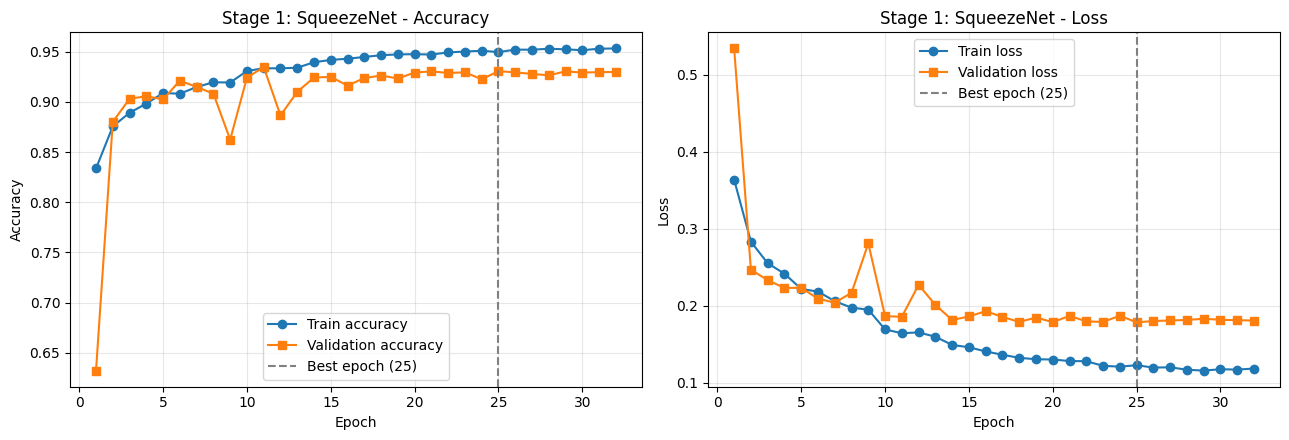

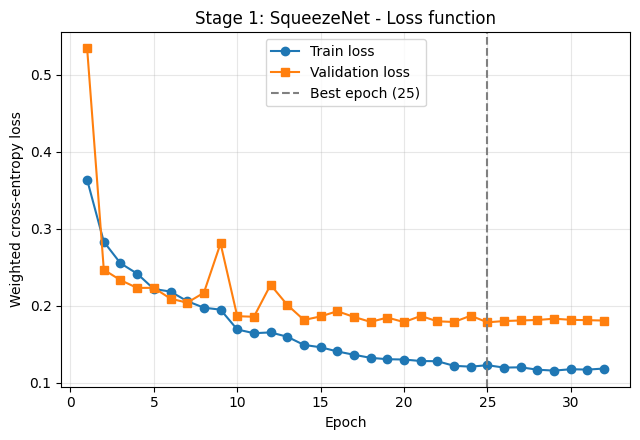


Stage 1 (SqueezeNet) - accuracy at best epoch


,Accuracy,Loss
Train,0.9516,0.1176
Validation,0.9306,0.1787
Test,0.9320,0.1759


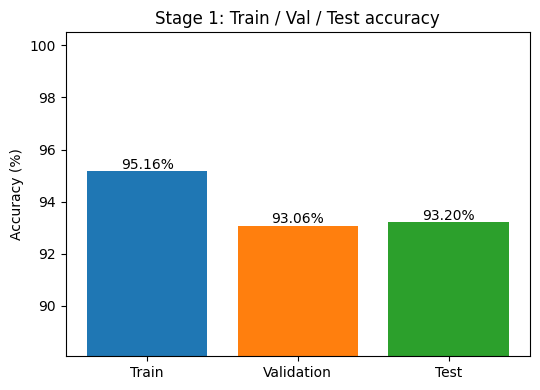

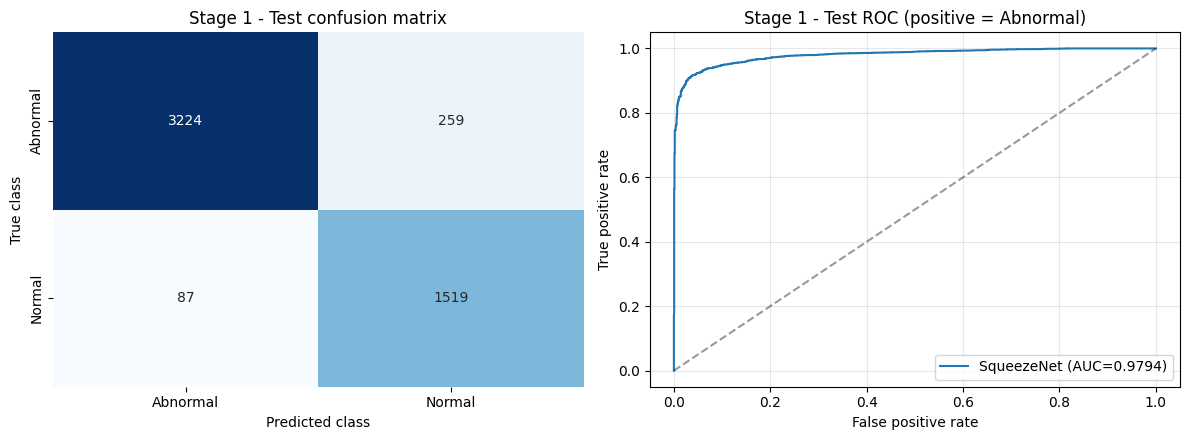

Test metrics:


,Stage,Model,Optimizer,Epochs_run,Best_epoch,Train_acc,Val_acc,Test_acc,Precision,Recall,Specificity,F1,FNR,AUC
value,Stage 1,SqueezeNet,ADAM,32,25,0.951649,0.930621,0.93201,0.973724,0.925639,0.945828,0.949073,0.074361,0.979417


In [ ]:
summary = []
summary.append(run_stage("Stage 1", y1, ["Abnormal", "Normal"]))

## 7. Stage 2 – ResNet-50: COVID-19 vs Non-COVID (abnormal images only)

Train      :  16743 images  (COVID-19 8369, Non-COVID 8374)
Validation :   3588 images  (COVID-19 1793, Non-COVID 1795)
Test       :   3588 images  (COVID-19 1794, Non-COVID 1794)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 138MB/s]



===== Stage 2: ResNet-50 | adam lr=0.0001 batch=32 dropout=0.5 =====
Epoch 01/40 | train loss 0.1916 acc 0.9171 | val loss 0.1624 acc 0.9384 | lr 1.0e-04 | 77s  <- best
Epoch 02/40 | train loss 0.0775 acc 0.9720 | val loss 0.0801 acc 0.9741 | lr 1.0e-04 | 76s  <- best
Epoch 03/40 | train loss 0.0556 acc 0.9787 | val loss 0.1295 acc 0.9582 | lr 1.0e-04 | 76s
Epoch 04/40 | train loss 0.0447 acc 0.9841 | val loss 0.1684 acc 0.9339 | lr 5.0e-05 | 76s
Epoch 05/40 | train loss 0.0250 acc 0.9910 | val loss 0.0701 acc 0.9766 | lr 5.0e-05 | 76s  <- best
Epoch 06/40 | train loss 0.0201 acc 0.9918 | val loss 0.0989 acc 0.9668 | lr 5.0e-05 | 76s
Epoch 07/40 | train loss 0.0175 acc 0.9941 | val loss 0.0709 acc 0.9785 | lr 2.5e-05 | 76s
Epoch 08/40 | train loss 0.0118 acc 0.9965 | val loss 0.0297 acc 0.9914 | lr 2.5e-05 | 76s  <- best
Epoch 09/40 | train loss 0.0099 acc 0.9974 | val loss 0.0410 acc 0.9869 | lr 2.5e-05 | 76s
Epoch 10/40 | train loss 0.0085 acc 0.9976 | val loss 0.0744 acc 0.9802 | l

,epoch,train_loss,val_loss,train_acc,val_acc,lr
0,1,0.1916,0.1624,0.9171,0.9384,0.0001
1,2,0.0775,0.0801,0.9720,0.9741,0.0001
2,3,0.0556,0.1295,0.9787,0.9582,0.0001
3,4,0.0447,0.1684,0.9841,0.9339,0.0000
4,5,0.0250,0.0701,0.9910,0.9766,0.0000
5,6,0.0201,0.0989,0.9918,0.9668,0.0000
6,7,0.0175,0.0709,0.9941,0.9785,0.0000
7,8,0.0118,0.0297,0.9965,0.9914,0.0000
8,9,0.0099,0.0410,0.9974,0.9869,0.0000
9,10,0.0085,0.0744,0.9976,0.9802,0.0000


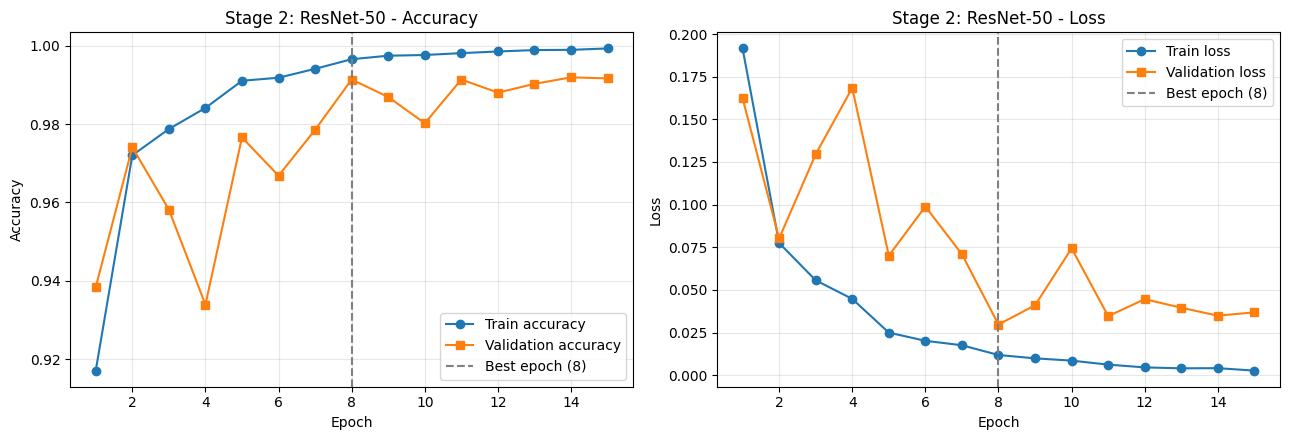

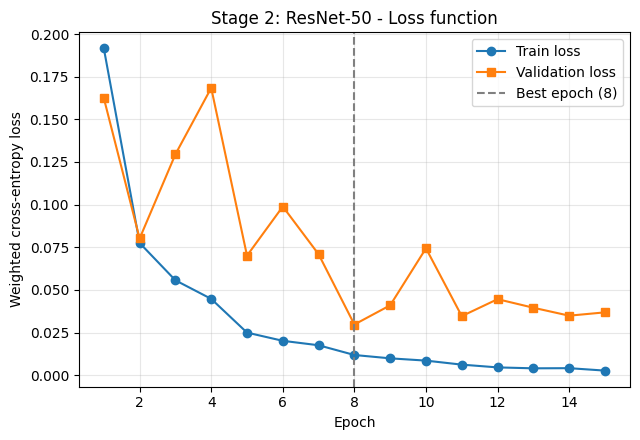


Stage 2 (ResNet-50) - accuracy at best epoch


,Accuracy,Loss
Train,0.9980,0.0056
Validation,0.9914,0.0297
Test,0.9925,0.0233


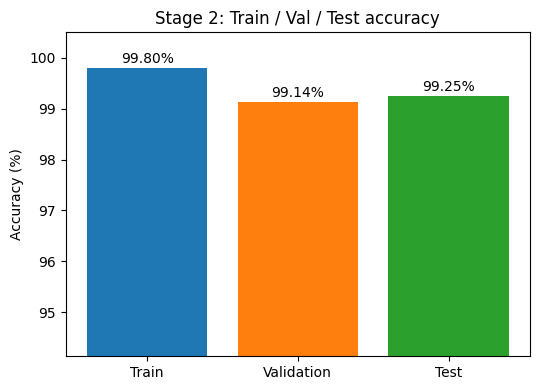

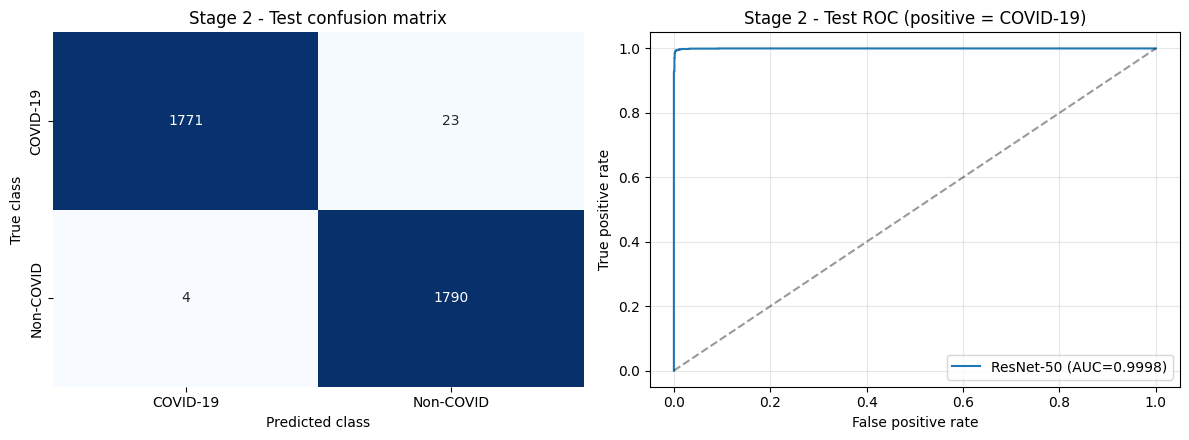

Test metrics:


,Stage,Model,Optimizer,Epochs_run,Best_epoch,Train_acc,Val_acc,Test_acc,Precision,Recall,Specificity,F1,FNR,AUC
value,Stage 2,ResNet-50,ADAM,15,8,0.998029,0.99136,0.992475,0.997746,0.987179,0.99777,0.992435,0.012821,0.999772


In [ ]:
summary.append(run_stage("Stage 2", y2, ["COVID-19", "Non-COVID"]))

## 8. Stage 3 - EfficientNet-b0: Pneumonia-Bacteria / Pneumonia-Virus / Tuberculosis (multiclass)
COVID-QU-Ex *Non-COVID* images are named `non_COVID (n).png`, i.e. they have **no bacterial / viral label**. So the bacterial and viral pneumonia images are taken from the **Chest X-Ray Images (Pneumonia)** dataset (Kermany et al., Kaggle `paultimothymooney/chest-xray-pneumonia`), where the label is in the file name (`..._bacteria_...`, `..._virus_...`). Tuberculosis images come from the TB dataset.

In [ ]:
os.makedirs("/content/data/pneu", exist_ok=True)
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/data/pneu --unzip -q
print("Downloaded")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
Downloaded


In [ ]:
S3_CLASSES = ["Pneumonia Bacteria", "Pneumonia Virus", "Tuberculosis"]

# bacterial / viral pneumonia: label is in the file name (train + val + test folders pooled; duplicates removed)
k_paths, k_labels, seen = [], [], set()
for root, _, fnames in os.walk("/content/data/pneu"):
    if "__MACOSX" in root: continue
    for f in fnames:
        fl = f.lower()
        if not fl.endswith(EXT) or f in seen: continue
        if "bacteria" in fl:
            k_paths.append(os.path.join(root, f)); k_labels.append(0); seen.add(f)
        elif "virus" in fl:
            k_paths.append(os.path.join(root, f)); k_labels.append(1); seen.add(f)

with ThreadPoolExecutor(16) as ex:
    Xk = np.stack(list(tqdm(ex.map(load_img, k_paths), total=len(k_paths), desc="Loading pneumonia images")))

# tuberculosis images are already cached in X
tb_idx = np.where((df.source == "TB/Tuberculosis").values)[0]
X3 = np.concatenate([X[tb_idx], Xk])
y3 = np.concatenate([np.full(len(tb_idx), 2), np.array(k_labels)]).astype(np.int64)
print("X3:", X3.shape, {S3_CLASSES[k]: int((y3 == k).sum()) for k in range(3)})
assert (y3 == 0).sum() > 0 and (y3 == 1).sum() > 0, "No bacteria/virus images found - check /content/data/pneu"

Loading pneumonia images:   0%|          | 0/4273 [00:00<?, ?it/s]

X3: (4973, 224, 224) {'Pneumonia Bacteria': 2780, 'Pneumonia Virus': 1493, 'Tuberculosis': 700}


### 8.3 Why Stage 3 over-fits, and the optimised method used below
Stage 3 has only ~5,000 images (TB = 700), so a large pretrained network memorises the training set quickly. Changes made:

| Problem | Fix |
|---|---|
| Same patient in train **and** val/test (Kermany files are `personN_...`, many images per patient) -> unreliable scores | **Patient-level split** (`StratifiedGroupKFold`), ~70/15/15 |
| Whole network fine-tuned at once with a high LR -> memorises | **2-phase transfer learning**: head only (frozen backbone), then full fine-tuning with a small LR for the backbone |
| Weak augmentation | **Stronger augmentation**: affine + brightness/contrast + random erasing |
| TB is a small class | **WeightedRandomSampler** (balanced batches) instead of only class weights |
| Over-confident outputs | **Label smoothing 0.1**, **Dropout 0.5**, **AdamW weight-decay**, **gradient clipping**, cosine LR |
| Accuracy hides weak classes | Best epoch picked by **validation macro-F1**, early stopping on it |

In [ ]:
import re
from sklearn.model_selection import StratifiedGroupKFold

# patient / group id for every image of X3  (same order as X3 = [TB images] + [Kermany images])
g_list = [f"tb_{i}" for i in range(len(tb_idx))]                       # TB has no patient id -> each image is its own group
for p, lab in zip(k_paths, k_labels):
    m = re.search(r"person(\d+)", os.path.basename(p).lower())
    g_list.append(f"{'bac' if lab == 0 else 'vir'}_{m.group(1)}" if m else f"unk_{p}")
g3 = np.array(g_list)
print("Unique patients/groups:", len(set(g3)), "| images:", len(g3))

# ~70 / 15 / 15 patient-level split (7 folds: fold0 = test, fold1 = validation, rest = train)
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(np.zeros(len(y3)), y3, g3)]
te3, va3, tr3 = folds[0], folds[1], np.concatenate(folds[2:])
assert not (set(g3[tr3]) & set(g3[va3])) and not (set(g3[tr3]) & set(g3[te3])) and not (set(g3[va3]) & set(g3[te3])), "patient leakage!"
for nm, ix in [("Train", tr3), ("Validation", va3), ("Test", te3)]:
    c = np.bincount(y3[ix], minlength=3)
    print(f"{nm:<11}: {len(ix):5d} images | " + ", ".join(f"{S3_CLASSES[k]} {c[k]}" for k in range(3)))
print("No patient appears in more than one split.")

Unique patients/groups: 3353 | images: 4973
Train      :  3513 images | Pneumonia Bacteria 1938, Pneumonia Virus 1077, Tuberculosis 498
Validation :   722 images | Pneumonia Bacteria 416, Pneumonia Virus 204, Tuberculosis 102
Test       :   738 images | Pneumonia Bacteria 426, Pneumonia Virus 212, Tuberculosis 100
No patient appears in more than one split.


In [ ]:
from torch.utils.data import WeightedRandomSampler

class CXRStrong(CXR):
    """Same as CXR but with stronger augmentation (training images only)."""
    def __init__(self, X, y, idx, train):
        super().__init__(X, y, idx, train)
        self.aug = v2.Compose([
            v2.RandomAffine(degrees=ROT, translate=(TRANSLATE, TRANSLATE), scale=(0.85, 1.15),
                            interpolation=InterpolationMode.BILINEAR),
            v2.ColorJitter(brightness=0.25, contrast=0.25),
            v2.RandomErasing(p=0.25, scale=(0.02, 0.10), value=0),
        ])

def run_stage3_optimized(tr, va, te, warm_epochs=5, max_epochs=30, patience=6):
    stage, mname, tag, n, class_names = "Stage 3", "EfficientNet-b0", "stage3", 3, S3_CLASSES
    cnt = np.bincount(y3[tr], minlength=n)
    sampler = WeightedRandomSampler(torch.tensor((1.0 / cnt)[y3[tr]], dtype=torch.double), num_samples=len(tr), replacement=True)
    train_dl = DataLoader(CXRStrong(X3, y3, tr, True), batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0)
    mk = lambda ix: DataLoader(CXR(X3, y3, ix, False), batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    train_eval_dl, val_dl, test_dl = mk(tr), mk(va), mk(te)
    ce_plain, ce_smooth = nn.CrossEntropyLoss(), nn.CrossEntropyLoss(label_smoothing=0.1)

    model = build_model(mname, n)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

    def set_phase(phase):
        for p_ in model.features.parameters(): p_.requires_grad = (phase == 2)
        if phase == 1:                                   # phase 1: only the new classifier head is trained
            return torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-2), None
        opt_ = torch.optim.AdamW([{"params": model.features.parameters(), "lr": 3e-5},      # backbone: small LR
                                  {"params": model.classifier.parameters(), "lr": 3e-4}],   # head: larger LR
                                 weight_decay=5e-2)
        return opt_, torch.optim.lr_scheduler.CosineAnnealingLR(opt_, T_max=max_epochs, eta_min=1e-6)

    opt, sched = set_phase(1)
    hist = dict(epoch=[], train_loss=[], val_loss=[], train_acc=[], val_acc=[], val_f1=[], lr=[])
    best_f1, best_state, best_ep, wait = -1, None, 0, 0
    print(f"===== Stage 3: EfficientNet-b0 | phase 1 = {warm_epochs} head-only epochs, phase 2 = up to {max_epochs} fine-tune epochs =====")
    for ep in range(1, warm_epochs + max_epochs + 1):
        if ep == warm_epochs + 1:
            opt, sched = set_phase(2); print("--- phase 2: backbone unfrozen ---")
        t0 = time.time(); model.train()
        if ep <= warm_epochs: model.features.eval()      # frozen backbone: keep BatchNorm statistics fixed
        tl, tc, tn = 0, 0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=device.type == "cuda"):
                out = model(xb); loss = ce_smooth(out, yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            with torch.no_grad(): tl += ce_plain(out.float(), yb).item() * len(yb)
            tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        vl, va_acc, pv, lv = evaluate(model, val_dl, ce_plain)
        vf1 = f1_score(lv, pv.argmax(1), average="macro")
        lr_now = opt.param_groups[-1]["lr"]
        if sched is not None: sched.step()
        for k, v in zip(hist.keys(), [ep, tl/tn, vl, tc/tn, va_acc, vf1, lr_now]): hist[k].append(v)
        flag = ""
        if vf1 > best_f1 + 1e-4:
            best_f1, best_ep, wait = vf1, ep, 0; best_state = copy.deepcopy(model.state_dict()); flag = "  <- best"
        elif ep > warm_epochs:
            wait += 1
        print(f"Epoch {ep:02d} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va_acc:.4f} macroF1 {vf1:.4f} "
              f"| lr {lr_now:.1e} | {time.time()-t0:.0f}s{flag}")
        if ep > warm_epochs and wait >= patience:
            print(f"Early stopping at epoch {ep} (best epoch = {best_ep})"); break
    model.load_state_dict(best_state); torch.save(best_state, f"results/{tag}_{mname}_best.pt")
    hist = pd.DataFrame(hist); hist.to_csv(f"results/{tag}_history.csv", index=False); HIST[stage] = hist
    print(f"\nStage 3 - epochs run: {len(hist)} | best epoch: {best_ep} | best val macro-F1: {best_f1:.4f}")
    display(hist.round(4)); plot_history(f"{stage}: {mname}", hist, best_ep, f"results/{tag}_curves.png")

    acc_rows = {}
    for nm, dl in [("Train", train_eval_dl), ("Validation", val_dl), ("Test", test_dl)]:
        l, a, p, lab = evaluate(model, dl, ce_plain); acc_rows[nm] = (a, l)
        if nm == "Test": p_te, lab_te = p, lab
    acc_df = pd.DataFrame(acc_rows, index=["Accuracy", "Loss"]).T
    print("Stage 3 (EfficientNet-b0) - accuracy at best epoch"); display(acc_df.round(4))
    print(f"Train-Test accuracy gap: {(acc_rows['Train'][0] - acc_rows['Test'][0]) * 100:.2f} points (smaller = less over-fitting)")
    plt.figure(figsize=(5.5, 4)); bars = plt.bar(acc_df.index, acc_df.Accuracy * 100, color=["tab:blue", "tab:orange", "tab:green"])
    for b_, v in zip(bars, acc_df.Accuracy * 100): plt.text(b_.get_x() + b_.get_width()/2, v + .1, f"{v:.2f}%", ha="center")
    plt.ylim(max(0, acc_df.Accuracy.min()*100 - 5), 100.5); plt.ylabel("Accuracy (%)"); plt.title("Stage 3: Train / Val / Test accuracy")
    plt.tight_layout(); plt.savefig(f"results/{tag}_split_accuracy.png", dpi=150); plt.show()
    cfg3 = dict(opt="adamw")
    return multiclass_report(stage, mname, cfg3, hist, best_ep, acc_rows, p_te, lab_te, class_names, tag)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 193MB/s]

===== Stage 3: EfficientNet-b0 | phase 1 = 5 head-only epochs, phase 2 = up to 30 fine-tune epochs =====


Epoch 01 | train loss 0.6228 acc 0.7296 | val loss 0.5044 acc 0.7825 macroF1 0.8038 | lr 1.0e-03 | 14s  <- best
Epoch 02 | train loss 0.4925 acc 0.7964 | val loss 0.5439 acc 0.7368 macroF1 0.7856 | lr 1.0e-03 | 11s
Epoch 03 | train loss 0.4651 acc 0.8091 | val loss 0.5421 acc 0.7410 macroF1 0.7902 | lr 1.0e-03 | 11s
Epoch 04 | train loss 0.4676 acc 0.8082 | val loss 0.4836 acc 0.7909 macroF1 0.8168 | lr 1.0e-03 | 11s  <- best
Epoch 05 | train loss 0.4511 acc 0.8174 | val loss 0.4726 acc 0.7950 macroF1 0.8176 | lr 1.0e-03 | 13s  <- best
--- phase 2: backbone unfrozen ---
Epoch 06 | train loss 0.6171 acc 0.7070 | val loss 0.5065 acc 0.7576 macroF1 0.7941 | lr 3.0e-04 | 17s
Epoch 07 | train loss 0.4780 acc 0.7881 | val loss 0.4645 acc 0.7839 macroF1 0.8097 | lr 3.0e-04 | 14s
Epoch 08 | train loss 0.4324 acc 0.8165 | val loss 0.4597 acc 0.7992 macroF1 0.8195 | lr 3.0e-04 | 14s  <- best
Epoch 09 | train loss 0.4392 acc 0.8220 | val loss 0.4468 acc 0.8006 macroF1 0.8219 | lr 2.9e-04 | 15s  <

,epoch,train_loss,val_loss,train_acc,val_acc,val_f1,lr
0,1,0.6228,0.5044,0.7296,0.7825,0.8038,0.0010
1,2,0.4925,0.5439,0.7964,0.7368,0.7856,0.0010
2,3,0.4651,0.5421,0.8091,0.7410,0.7902,0.0010
3,4,0.4676,0.4836,0.8082,0.7909,0.8168,0.0010
4,5,0.4511,0.4726,0.8174,0.7950,0.8176,0.0010
5,6,0.6171,0.5065,0.7070,0.7576,0.7941,0.0003
6,7,0.4780,0.4645,0.7881,0.7839,0.8097,0.0003
7,8,0.4324,0.4597,0.8165,0.7992,0.8195,0.0003
8,9,0.4392,0.4468,0.8220,0.8006,0.8219,0.0003
9,10,0.4263,0.4889,0.8231,0.7798,0.8176,0.0003


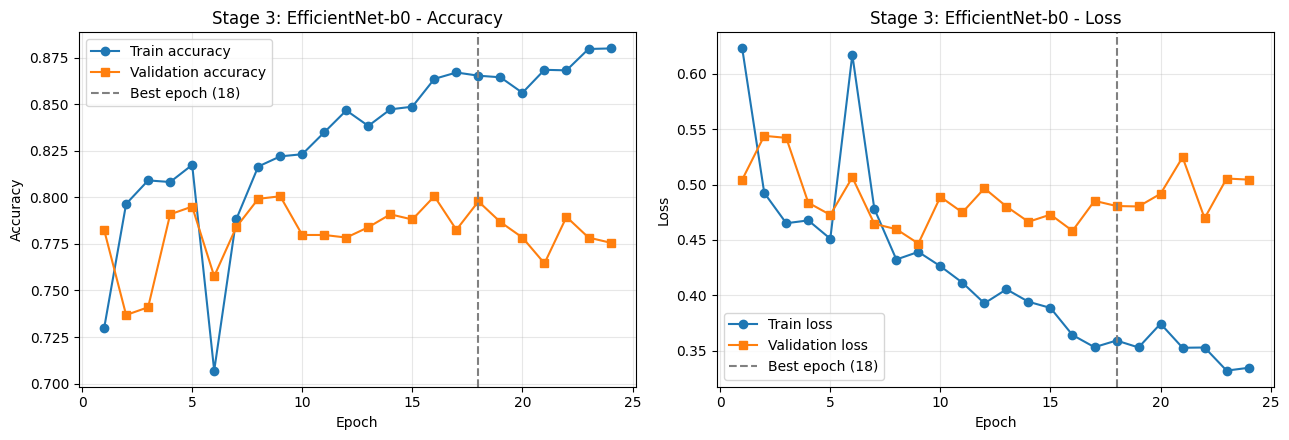

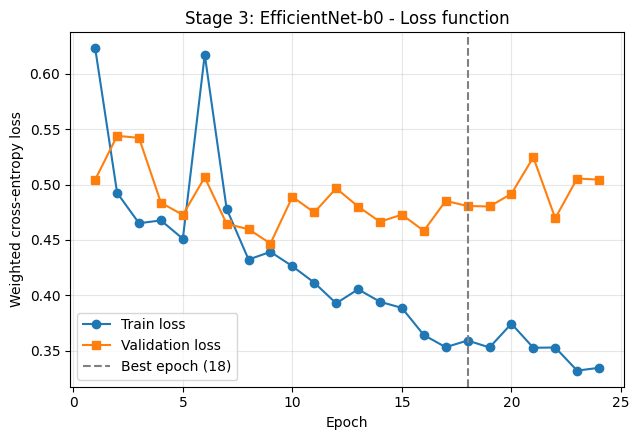

Stage 3 (EfficientNet-b0) - accuracy at best epoch


,Accuracy,Loss
Train,0.8480,0.3815
Validation,0.7978,0.4806
Test,0.8360,0.4211


Train-Test accuracy gap: 1.19 points (smaller = less over-fitting)


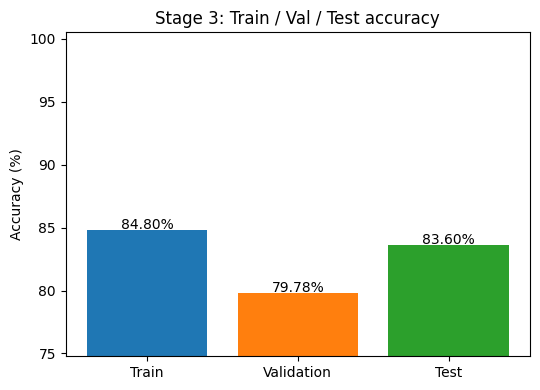

Stage 3 - TEST per-class report
                    precision    recall  f1-score   support

Pneumonia Bacteria     0.9024    0.8028    0.8497       426
   Pneumonia Virus     0.6757    0.8255    0.7431       212
      Tuberculosis     1.0000    1.0000    1.0000       100

          accuracy                         0.8360       738
         macro avg     0.8594    0.8761    0.8643       738
      weighted avg     0.8505    0.8360    0.8394       738



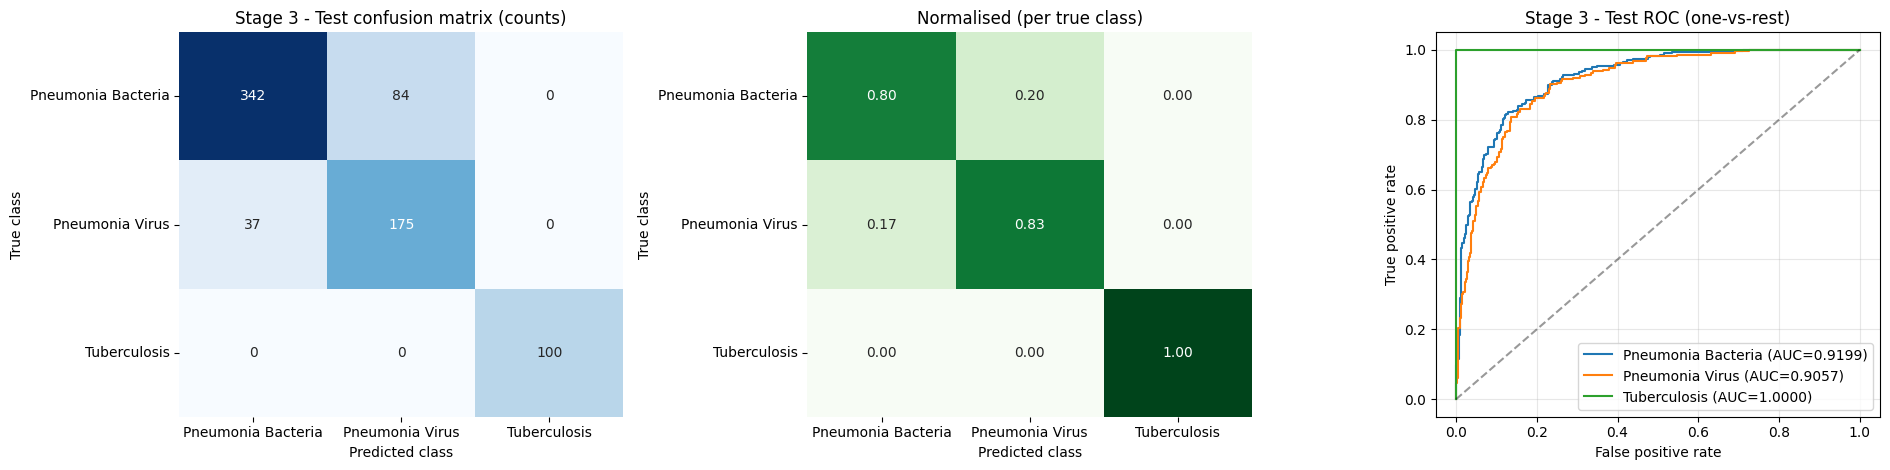

Test metrics (macro-averaged):


,Stage,Model,Optimizer,Epochs_run,Best_epoch,Train_acc,Val_acc,Test_acc,Precision,Recall,F1,AUC
value,Stage 3,EfficientNet-b0,ADAMW,24,18,0.847993,0.797784,0.836043,0.85935,0.876096,0.864263,0.94187


In [ ]:
summary.append(run_stage3_optimized(tr3, va3, te3))

### 8.4 Stage 3 v2 - fixing the real problem: **under-fitting**, not over-fitting
Result of the cell above: **Train 82.0 % | Val 79.8 % | Test 81.6 %** -> the gap is only 0.4 points, so the network is *not* memorising.
It simply cannot fit the data (train accuracy itself is only 82 %). The previous "anti-overfitting" recipe was too strong, so this version loosens it and gives the model more signal:

| What limited accuracy | Change in v2 |
|---|---|
| 224 px loses the fine lung texture needed for **bacteria vs virus** | images re-loaded at **320 px** (`S3_SIZE`) |
| Backbone LR 3e-5 + 5 frozen head-only epochs = barely learns | **whole network trained from epoch 1**, backbone LR 2e-4, head LR 1e-3, **OneCycle** (warm-up + cosine) |
| Too many regularisers together (label smoothing, RandomErasing, strong colour jitter, wd 5e-2, dropout 0.5) | label smoothing **off**, RandomErasing **off**, mild affine + mild contrast only, wd 1e-2, dropout 0.3 |
| Early stopping cut training at epoch 15 while LR was still high | fixed **30 epochs**, LR fully annealed, best epoch = best **validation macro-F1** |

Patient-level split (no leakage), balanced sampler and gradient clipping are kept. If test accuracy is still below 90 %, set `S3_BACKBONE = "efficientnet_b2"` and run again.

Stage-3 images @ 320px:   0%|          | 0/4973 [00:00<?, ?it/s]

X3h: (4973, 320, 320) | 0.51 GB
===== Stage 3 v2: EfficientNet-b0 | 320px | 30 epochs | AdamW + OneCycle | train 3513 / val 722 / test 738 =====
Epoch 01/30 | train loss 0.8994 acc 0.6181 | val loss 0.6073 acc 0.7410 macroF1 0.7821 | lr 3.1e-05 | 26s  <- best
Epoch 02/30 | train loss 0.4247 acc 0.8185 | val loss 0.4576 acc 0.8019 macroF1 0.8304 | lr 8.8e-05 | 23s  <- best
Epoch 03/30 | train loss 0.3528 acc 0.8417 | val loss 0.4797 acc 0.7770 macroF1 0.8169 | lr 1.5e-04 | 23s
Epoch 04/30 | train loss 0.3087 acc 0.8696 | val loss 0.4387 acc 0.8033 macroF1 0.8304 | lr 1.9e-04 | 23s
Epoch 05/30 | train loss 0.2721 acc 0.8827 | val loss 0.4768 acc 0.8033 macroF1 0.8292 | lr 2.0e-04 | 23s
Epoch 06/30 | train loss 0.2447 acc 0.8959 | val loss 0.5616 acc 0.7729 macroF1 0.8142 | lr 2.0e-04 | 23s
Epoch 07/30 | train loss 0.2249 acc 0.9062 | val loss 0.6327 acc 0.7493 macroF1 0.7947 | lr 2.0e-04 | 23s
Epoch 08/30 | train loss 0.1886 acc 0.9266 | val loss 0.6697 acc 0.7548 macroF1 0.8023 | lr 1.9

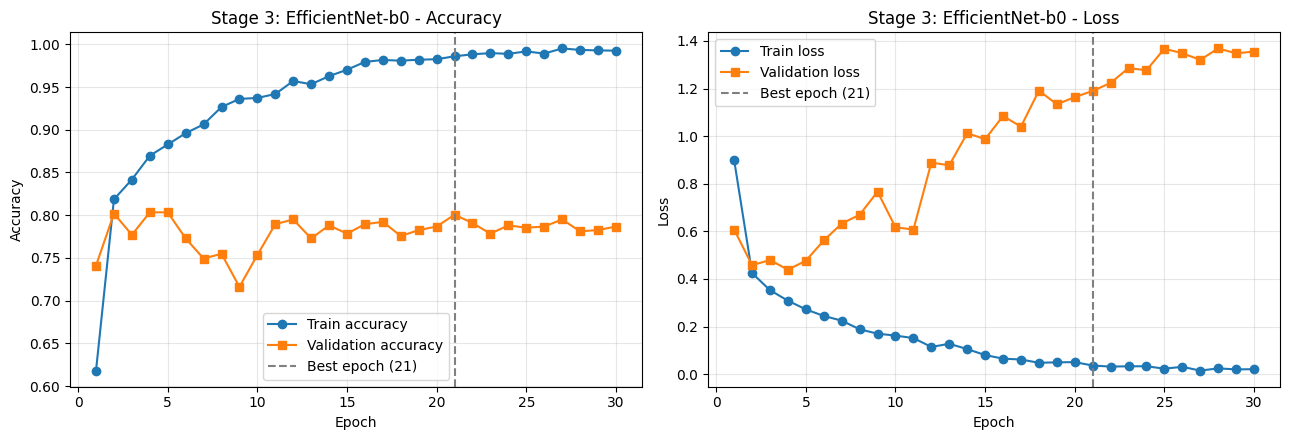

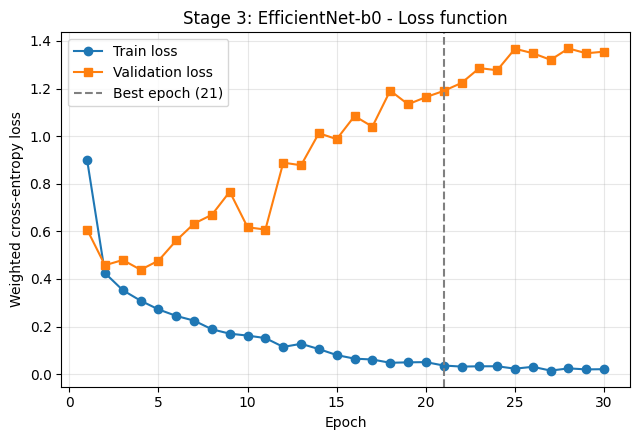

Stage 3 v2 (EfficientNet-b0) - accuracy at best epoch


,Accuracy,Loss
Train,0.9906,0.0275
Validation,0.8006,1.1899
Test,0.8306,0.8037


Train-Test gap: 16.00 points
Bacteria-vs-Virus only (TB excluded) test accuracy: 80.41%   <- the really hard part


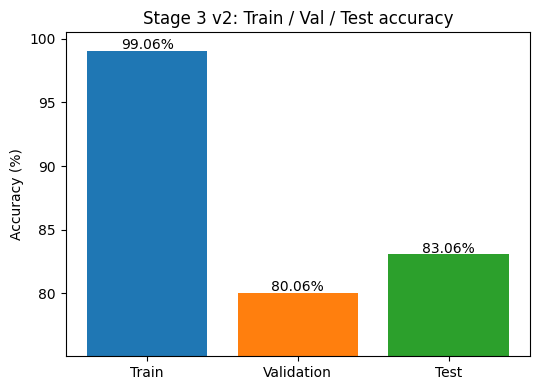

Stage 3 - TEST per-class report
                    precision    recall  f1-score   support

Pneumonia Bacteria     0.8889    0.8075    0.8462       426
   Pneumonia Virus     0.6733    0.7972    0.7300       212
      Tuberculosis     1.0000    1.0000    1.0000       100

          accuracy                         0.8306       738
         macro avg     0.8541    0.8682    0.8588       738
      weighted avg     0.8420    0.8306    0.8337       738



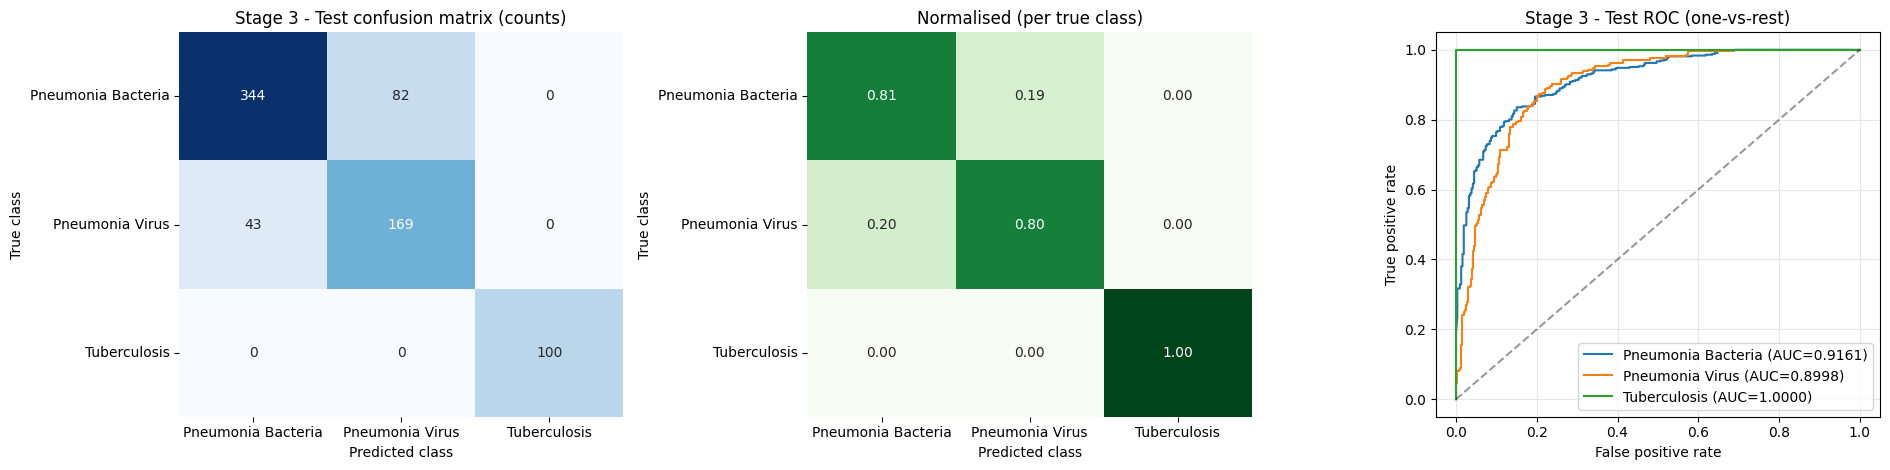

Test metrics (macro-averaged):


,Stage,Model,Optimizer,Epochs_run,Best_epoch,Train_acc,Val_acc,Test_acc,Precision,Recall,F1,AUC
value,Stage 3,EfficientNet-b0,ADAMW,30,21,0.990606,0.800554,0.830623,0.854065,0.868227,0.858757,0.938644


In [ ]:
# ================= Stage 3 v2 : EfficientNet, fixes UNDER-fitting =================
import time, copy
from torch.utils.data import WeightedRandomSampler

# ---------------- knobs ----------------
S3_BACKBONE = "efficientnet_b0"   # paper's network.  Still < 90 % ?  ->  "efficientnet_b2"
S3_SIZE     = 320                 # was 224
S3_EPOCHS   = 30
S3_BS       = 32
S3_BB_LR    = 2e-4                # backbone LR   (old: 3e-5)
S3_HEAD_LR  = 1e-3                # classifier head LR
S3_DROPOUT  = 0.3                 # old: 0.5
S3_WD       = 1e-2                # old: 5e-2
S3_CLASSES  = ["Pneumonia Bacteria", "Pneumonia Virus", "Tuberculosis"]

# ---------------- 1. re-load Stage-3 images at higher resolution (same order as X3 / y3 / g3) ----------------
def load_img_sz(p):
    im = Image.open(p).convert("L").resize((S3_SIZE, S3_SIZE), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

tb_paths = df.path.values[tb_idx].tolist()
with ThreadPoolExecutor(16) as ex:
    X3h = np.stack(list(tqdm(ex.map(load_img_sz, tb_paths + k_paths),
                             total=len(tb_paths) + len(k_paths), desc=f"Stage-3 images @ {S3_SIZE}px")))
assert len(X3h) == len(y3) == len(g3), "image order mismatch"
print("X3h:", X3h.shape, f"| {X3h.nbytes/1e9:.2f} GB")

# ---------------- 2. mild augmentation (training images only) ----------------
class CXRAug(CXR):
    def __init__(self, X, y, idx, train):
        super().__init__(X, y, idx, train)
        self.aug = v2.Compose([
            v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.92, 1.08), interpolation=InterpolationMode.BILINEAR),
            v2.ColorJitter(brightness=0.15, contrast=0.15),
        ])

# ---------------- 3. model ----------------
def build_eff(backbone, n_classes, dropout=S3_DROPOUT, pretrained=True):
    if backbone == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
    elif backbone == "efficientnet_b2":
        m = models.efficientnet_b2(weights=models.EfficientNet_B2_Weights.DEFAULT if pretrained else None)
    else:
        raise ValueError(backbone)
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, n_classes))
    return m.to(device)

# ---------------- 4. train / evaluate ----------------
def run_stage3_v2(tr, va, te):
    stage, tag, n = "Stage 3", "stage3v2", 3
    mname = {"efficientnet_b0": "EfficientNet-b0", "efficientnet_b2": "EfficientNet-b2"}[S3_BACKBONE]
    CFG["Stage 3"]["model"] = mname                      # label used by the summary plots
    cnt = np.bincount(y3[tr], minlength=n)
    sampler = WeightedRandomSampler(torch.tensor((1.0 / cnt)[y3[tr]], dtype=torch.double), num_samples=len(tr), replacement=True)
    train_dl = DataLoader(CXRAug(X3h, y3, tr, True), batch_size=S3_BS, sampler=sampler, num_workers=NUM_WORKERS,
                          pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0)
    mk = lambda ix: DataLoader(CXR(X3h, y3, ix, False), batch_size=S3_BS * 2, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    train_eval_dl, val_dl, test_dl = mk(tr), mk(va), mk(te)
    ce = nn.CrossEntropyLoss()                           # plain CE (no label smoothing): the model was under-fitting

    model = build_eff(S3_BACKBONE, n)
    opt = torch.optim.AdamW([{"params": model.features.parameters(),   "lr": S3_BB_LR},
                             {"params": model.classifier.parameters(), "lr": S3_HEAD_LR}], weight_decay=S3_WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[S3_BB_LR, S3_HEAD_LR], total_steps=S3_EPOCHS * len(train_dl),
                                                pct_start=0.15, anneal_strategy="cos", cycle_momentum=False)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

    hist = dict(epoch=[], train_loss=[], val_loss=[], train_acc=[], val_acc=[], val_f1=[], lr=[])
    best_f1, best_state, best_ep = -1.0, None, 0
    print(f"===== Stage 3 v2: {mname} | {S3_SIZE}px | {S3_EPOCHS} epochs | AdamW + OneCycle | train {len(tr)} / val {len(va)} / test {len(te)} =====")
    for ep in range(1, S3_EPOCHS + 1):
        t0 = time.time(); model.train(); tl = tc = tn = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=device.type == "cuda"):
                out = model(xb); loss = ce(out, yb)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); tn += len(yb)
        vl, va_acc, pv, lv = evaluate(model, val_dl, ce)
        vf1 = f1_score(lv, pv.argmax(1), average="macro")
        lr_now = opt.param_groups[0]["lr"]
        for k, v in zip(hist.keys(), [ep, tl / tn, vl, tc / tn, va_acc, vf1, lr_now]): hist[k].append(v)
        flag = ""
        if vf1 > best_f1 + 1e-4:
            best_f1, best_ep = vf1, ep; best_state = copy.deepcopy(model.state_dict()); flag = "  <- best"
        print(f"Epoch {ep:02d}/{S3_EPOCHS} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl:.4f} acc {va_acc:.4f} "
              f"macroF1 {vf1:.4f} | lr {lr_now:.1e} | {time.time()-t0:.0f}s{flag}")
    model.load_state_dict(best_state); torch.save(best_state, f"results/{tag}_{S3_BACKBONE}_best.pt")
    hist = pd.DataFrame(hist); hist.to_csv(f"results/{tag}_history.csv", index=False); HIST[stage] = hist
    print(f"\nStage 3 v2 - best epoch: {best_ep} | best val macro-F1: {best_f1:.4f}")
    plot_history(f"{stage}: {mname}", hist, best_ep, f"results/{tag}_curves.png")

    acc_rows = {}
    for nm, dl in [("Train", train_eval_dl), ("Validation", val_dl), ("Test", test_dl)]:
        l, a, p, lab = evaluate(model, dl, ce); acc_rows[nm] = (a, l)
        if nm == "Test": p_te, lab_te = p, lab
    acc_df = pd.DataFrame(acc_rows, index=["Accuracy", "Loss"]).T
    print(f"Stage 3 v2 ({mname}) - accuracy at best epoch"); display(acc_df.round(4))
    print(f"Train-Test gap: {(acc_rows['Train'][0] - acc_rows['Test'][0]) * 100:.2f} points")
    pred = p_te.argmax(1); nt = lab_te != 2
    print(f"Bacteria-vs-Virus only (TB excluded) test accuracy: {(pred[nt] == lab_te[nt]).mean() * 100:.2f}%   <- the really hard part")
    plt.figure(figsize=(5.5, 4)); bars = plt.bar(acc_df.index, acc_df.Accuracy * 100, color=["tab:blue", "tab:orange", "tab:green"])
    for b_, v in zip(bars, acc_df.Accuracy * 100): plt.text(b_.get_x() + b_.get_width() / 2, v + .1, f"{v:.2f}%", ha="center")
    plt.ylim(max(0, acc_df.Accuracy.min() * 100 - 5), 100.5); plt.ylabel("Accuracy (%)"); plt.title("Stage 3 v2: Train / Val / Test accuracy")
    plt.tight_layout(); plt.savefig(f"results/{tag}_split_accuracy.png", dpi=150); plt.show()
    return multiclass_report(stage, mname, dict(opt="adamw"), hist, best_ep, acc_rows, p_te, lab_te, S3_CLASSES, tag)

m3 = run_stage3_v2(tr3, va3, te3)
summary[:] = [s for s in summary if s["Stage"] != "Stage 3"] + [m3]     # replace the old Stage-3 row in the final summary

## 9. Summary of all three stages

,Model,Optimizer,Epochs_run,Best_epoch,Train_acc,Val_acc,Test_acc,Precision,Recall,Specificity,F1,FNR,AUC
Stage,,,,,,,,,,,,,
Stage 1,SqueezeNet,ADAM,32,25,0.9516,0.9306,0.9320,0.9737,0.9256,0.9458,0.9491,0.0744,0.9794
Stage 2,ResNet-50,ADAM,15,8,0.9980,0.9914,0.9925,0.9977,0.9872,0.9978,0.9924,0.0128,0.9998
Stage 3,EfficientNet-b0,ADAMW,30,21,0.9906,0.8006,0.8306,0.8541,0.8682,NaN,0.8588,NaN,0.9386


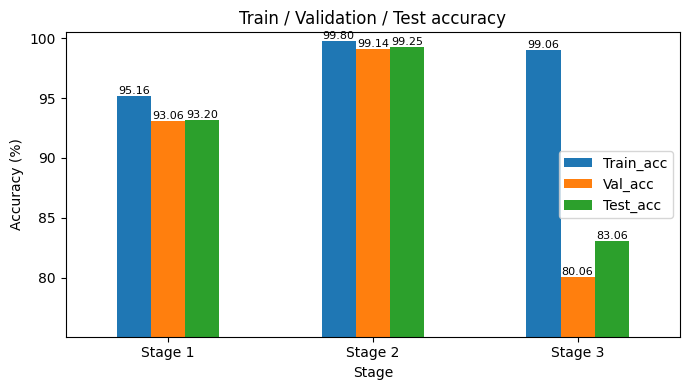

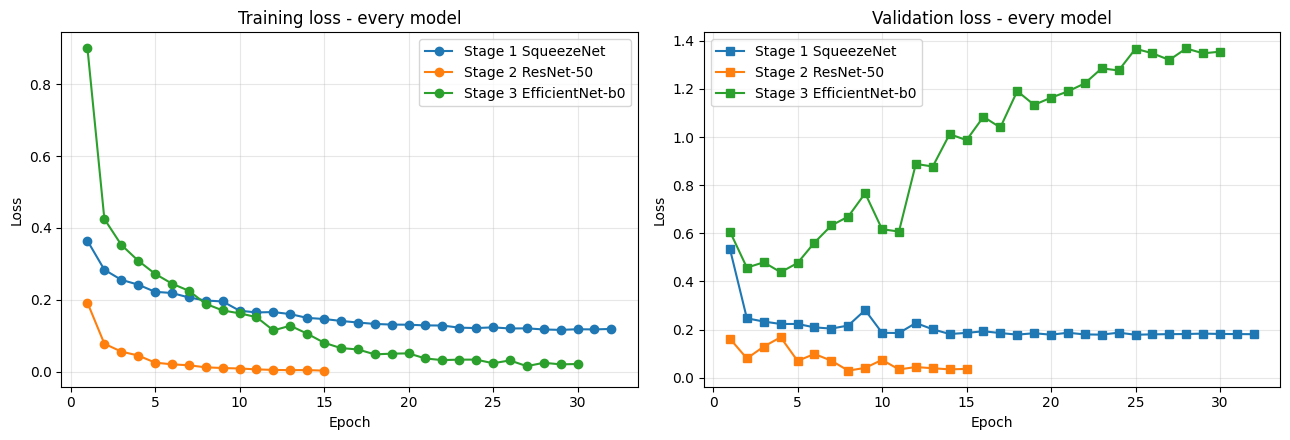

In [ ]:
sdf = pd.DataFrame(summary).set_index("Stage")
sdf.round(4).to_csv("results/summary_stage1_stage2.csv")
display(sdf.round(4))

ax = (sdf[["Train_acc", "Val_acc", "Test_acc"]] * 100).plot.bar(figsize=(7, 4), rot=0, color=["tab:blue", "tab:orange", "tab:green"])
ax.set_ylabel("Accuracy (%)"); ax.set_title("Train / Validation / Test accuracy"); ax.set_ylim(max(0, sdf[["Train_acc","Val_acc","Test_acc"]].min().min()*100 - 5), 100.5)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig("results/summary_accuracy.png", dpi=150); plt.show()

# loss function of every model on one figure
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for stg, h in HIST.items():
    mn = CFG[stg]["model"]
    ax[0].plot(h.epoch, h.train_loss, "o-", label=f"{stg} {mn}")
    ax[1].plot(h.epoch, h.val_loss, "s-", label=f"{stg} {mn}")
ax[0].set(title="Training loss - every model", xlabel="Epoch", ylabel="Loss"); ax[1].set(title="Validation loss - every model", xlabel="Epoch", ylabel="Loss")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/loss_all_models.png", dpi=150); plt.show()

## 10. Integrate all three models into one pipeline
`Normal?` -> **Stage 1 SqueezeNet** -> if Abnormal -> **Stage 2 ResNet-50** (COVID-19 or not) -> if Non-COVID -> **Stage 3 EfficientNet-b0** (bacterial pneumonia / viral pneumonia / TB).

The weights are loaded from the `results/` folder. In a **new session**: run Section 1 (imports + config) and Section 5 (functions), upload the `.pt` files into a `results/` folder, then run Sections 10, 11 and 12.

In [ ]:
import torch.nn.functional as F
STAGE_INFO = {
    1: dict(model="SqueezeNet",      file="results/stage1_SqueezeNet_best.pt",      classes=["Abnormal", "Normal"]),
    2: dict(model="ResNet-50",       file="results/stage2_ResNet-50_best.pt",       classes=["COVID-19", "Non-COVID"]),
    3: dict(model="EfficientNet-b0", file="results/stage3_EfficientNet-b0_best.pt", classes=["Pneumonia Bacteria", "Pneumonia Virus", "Tuberculosis"]),
}
PIPE = {}
for k, info in STAGE_INFO.items():
    m = build_model(info["model"], len(info["classes"]), pretrained=False)
    m.load_state_dict(torch.load(info["file"], map_location=device)); m.eval(); PIPE[k] = m
    print(f"Stage {k}: {info['model']} loaded  ->  {info['classes']}")

def preprocess(path):
    """Same preprocessing as training: grayscale -> 224x224 -> 3 channels -> ImageNet normalisation."""
    im = Image.open(path).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im, dtype=np.uint8)).unsqueeze(0).float().div(255).expand(3, -1, -1)
    return ((x - MEAN) / STD).unsqueeze(0).to(device), im

@torch.no_grad()
def predict_image(path, show=True):
    x, im = preprocess(path); steps = []
    def run(k):
        p = F.softmax(PIPE[k](x).float(), 1)[0].cpu().numpy(); i = int(p.argmax())
        return STAGE_INFO[k]["classes"][i], float(p[i])
    c1, p1 = run(1); steps.append(("Stage 1 (SqueezeNet)", c1, p1))
    if c1 == "Normal":
        final = "Normal - no abnormality detected"
    else:
        c2, p2 = run(2); steps.append(("Stage 2 (ResNet-50)", c2, p2))
        if c2 == "COVID-19":
            final = "COVID-19"
        else:
            c3, p3 = run(3); steps.append(("Stage 3 (EfficientNet-b0)", c3, p3)); final = c3
    if show:
        plt.figure(figsize=(5, 5.4)); plt.imshow(im, cmap="gray"); plt.axis("off")
        plt.title(f"Prediction: {final}", fontsize=12, color="darkred" if not final.startswith("Normal") else "darkgreen"); plt.show()
        for st, c, p in steps: print(f"  {st:<27}-> {c:<20} confidence {p*100:5.1f}%")
        print("  (Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.)")
    return final, steps

Stage 1: SqueezeNet loaded  ->  ['Abnormal', 'Normal']
Stage 2: ResNet-50 loaded  ->  ['COVID-19', 'Non-COVID']
Stage 3: EfficientNet-b0 loaded  ->  ['Pneumonia Bacteria', 'Pneumonia Virus', 'Tuberculosis']


## 11. Grad-CAM - highlight the region of the chest X-ray that drives the prediction
Grad-CAM uses the gradients flowing into the last convolution layer of each network to build a heat-map (red = strong influence on the decision).
For an uploaded X-ray the figure shows: **(1)** the input, **(2)** where Stage 1 finds the *abnormality*, **(3)** the evidence for the *final diagnosis* (Stage 2 for COVID-19, Stage 3 for pneumonia / TB).

> The heat-map shows what the model looked at. It is **not** a verified segmentation of the infection and can also light up artefacts (letters, borders, tubes).

In [ ]:
CAM_LAYERS = {1: PIPE[1].features[-1],      # SqueezeNet : last Fire module
              2: PIPE[2].layer4[-1],        # ResNet-50  : last residual block
              3: PIPE[3].features[-1]}      # EfficientNet-b0 : last conv block

def grad_cam(stage_k, x, class_idx=None):
    """Returns (cam 224x224 in [0,1], class index used)."""
    model, layer, store = PIPE[stage_k], CAM_LAYERS[stage_k], {}
    def fwd_hook(module, inp, out):
        store["a"] = out.detach()
        out.register_hook(lambda g: store.__setitem__("g", g.detach()))
    handle = layer.register_forward_hook(fwd_hook)
    try:
        model.eval(); model.zero_grad(set_to_none=True)
        xin = x.clone().float().requires_grad_(True)
        with torch.enable_grad():
            logits = model(xin)
            if class_idx is None: class_idx = int(logits.argmax(1).item())
            logits[0, class_idx].backward()
    finally:
        handle.remove()
    a, g = store["a"][0], store["g"][0]                         # C x h x w
    cam = F.relu((g.mean(dim=(1, 2), keepdim=True) * a).sum(0)) # channel-weighted sum of feature maps
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy(), class_idx

def show_cam(ax, im, cam, title, thr=0.6):
    ax.imshow(im, cmap="gray"); ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax.contour(cam, levels=[thr], colors="white", linewidths=1.3)      # white outline = strongest region
    ax.set_title(title, fontsize=10); ax.axis("off")

def predict_with_gradcam(path, save=True):
    x, im = preprocess(path)
    def probs(k):
        with torch.no_grad():
            return F.softmax(PIPE[k](x).float(), 1)[0].cpu().numpy()
    cls = {k: STAGE_INFO[k]["classes"] for k in STAGE_INFO}
    steps = []
    p1 = probs(1); i1 = int(p1.argmax()); c1 = cls[1][i1]; steps.append(("Stage 1 (SqueezeNet)", c1, p1[i1]))
    if c1 == "Normal":
        final, conf, cams = "Normal - no abnormality detected", p1[i1], []
    else:
        cam1, _ = grad_cam(1, x, class_idx=0)                         # class 0 = Abnormal
        cams = [("Stage 1: where the model sees abnormality", cam1)]
        p2 = probs(2); i2 = int(p2.argmax()); c2 = cls[2][i2]; steps.append(("Stage 2 (ResNet-50)", c2, p2[i2]))
        if c2 == "COVID-19":
            final, conf = "COVID-19", p2[i2]
            cam_f, _ = grad_cam(2, x, class_idx=i2); cams.append((f"Stage 2: evidence for {final}", cam_f))
        else:
            p3 = probs(3); i3 = int(p3.argmax()); c3 = cls[3][i3]; steps.append(("Stage 3 (EfficientNet-b0)", c3, p3[i3]))
            final, conf = c3, p3[i3]
            cam_f, _ = grad_cam(3, x, class_idx=i3); cams.append((f"Stage 3: evidence for {final}", cam_f))
    n = 1 + len(cams)
    fig, ax = plt.subplots(1, n, figsize=(5 * n, 5.4)); ax = np.atleast_1d(ax)
    ax[0].imshow(im, cmap="gray"); ax[0].set_title("Input (as seen by the model)", fontsize=10); ax[0].axis("off")
    for a_, (t, c) in zip(ax[1:], cams): show_cam(a_, im, c, t)
    fig.suptitle(f"Prediction: {final}  ({conf*100:.1f}% confidence)", fontsize=13,
                 color="darkgreen" if final.startswith("Normal") else "darkred")
    plt.tight_layout()
    if save: plt.savefig(f"results/gradcam_{os.path.splitext(os.path.basename(path))[0]}.png", dpi=150, bbox_inches="tight")
    plt.show()
    for st, c, p in steps: print(f"  {st:<27}-> {c:<20} confidence {p*100:5.1f}%")
    print("  Heat-map = regions that influenced the model (red = strong); white outline = strongest area.")
    print("  Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.")
    return final, steps

Feature Map Visualization


In [ ]:
# ---- Feature-map visualisation for the uploaded image ----
FM_LAYERS = {   # shallow -> deep
    1: [("conv1", PIPE[1].features[1]), ("fire3", PIPE[1].features[4]), ("fire5", PIPE[1].features[7]),
        ("fire7", PIPE[1].features[10]), ("fire9", PIPE[1].features[12])],
    2: [("conv1", PIPE[2].relu), ("layer1", PIPE[2].layer1), ("layer2", PIPE[2].layer2),
        ("layer3", PIPE[2].layer3), ("layer4", PIPE[2].layer4)],
    3: [("stem", PIPE[3].features[0]), ("block2", PIPE[3].features[2]), ("block4", PIPE[3].features[4]),
        ("block6", PIPE[3].features[6]), ("last conv", PIPE[3].features[8])],
}

@torch.no_grad()
def get_feature_maps(stage_k, x):
    store, handles = {}, []
    for name, layer in FM_LAYERS[stage_k]:
        handles.append(layer.register_forward_hook(
            lambda m, i, o, n=name: store.__setitem__(n, o.detach().float().cpu().clone()[0])))
    try:
        PIPE[stage_k].eval(); PIPE[stage_k](x)
    finally:
        for h in handles: h.remove()
    out = []
    for name, _ in FM_LAYERS[stage_k]:
        a = store[name]                                   # C x h x w
        mean = F.interpolate(a.mean(0)[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
        out.append((name, a.numpy(), mean.numpy()))
    return out

def plot_feature_maps(maps, im, title, n_maps=8, save_path=None):
    rows = len(maps)
    fig = plt.figure(figsize=(1.75 * (n_maps + 1), 1.95 * rows))
    gs = fig.add_gridspec(rows, n_maps + 1, wspace=0.06, hspace=0.4)
    for r, (name, a, mean) in enumerate(maps):
        C, h, w = a.shape
        mean = (mean - mean.min()) / (mean.max() - mean.min() + 1e-8)
        ax = fig.add_subplot(gs[r, 0]); ax.imshow(im, cmap="gray"); ax.imshow(mean, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.set_title(f"{name}\n{C} ch | {h}x{w}", fontsize=9); ax.axis("off")
        for c, ch in enumerate(np.argsort(a.reshape(C, -1).mean(1))[::-1][:n_maps]):   # most active channels
            fm = a[ch]; fm = (fm - fm.min()) / (fm.max() - fm.min() + 1e-8)
            ax = fig.add_subplot(gs[r, c + 1]); ax.imshow(fm, cmap="viridis"); ax.set_title(f"ch {ch}", fontsize=8); ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.0)
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

def visualize_feature_maps(path, stages=None, n_maps=8, save=True):
    x, im = preprocess(path)
    if stages is None:                                    # only the stages this image really goes through
        _, steps = predict_image(path, show=False)
        stages = list(range(1, len(steps) + 1))
    for k in stages:
        sp = f"results/featuremaps_stage{k}_{os.path.splitext(os.path.basename(path))[0]}.png" if save else None
        plot_feature_maps(get_feature_maps(k, x), im, f"Stage {k} - {STAGE_INFO[k]['model']}: feature maps of the uploaded image", n_maps, sp)

## 11.5 Plug the optimised Stage 3 (v2) into the pipeline
Stage 3 v2 works at `S3_SIZE` px while Stage 1 / 2 were trained at 224 px. This cell loads the new Stage-3 weights and shrinks the input to 224 px *inside* Stage 1 and 2, so predictions, Grad-CAM and feature maps below keep working unchanged.
(New session? Run the Stage 3 v2 knobs + `build_eff` definition first, and keep `results/stage3v2_<backbone>_best.pt`.)

In [ ]:
S3_FILE = f"results/stage3v2_{S3_BACKBONE}_best.pt"
_m = build_eff(S3_BACKBONE, 3, pretrained=False)
_m.load_state_dict(torch.load(S3_FILE, map_location=device)); _m.eval()
PIPE[3] = _m
STAGE_INFO[3].update(model="EfficientNet (v2)", file=S3_FILE)
CAM_LAYERS[3] = PIPE[3].features[-1]
FM_LAYERS[3] = [("stem", PIPE[3].features[0]), ("block2", PIPE[3].features[2]), ("block4", PIPE[3].features[4]),
                ("block6", PIPE[3].features[6]), ("last conv", PIPE[3].features[8])]

IMG_SIZE = S3_SIZE                      # preprocess(), Grad-CAM and feature maps now run at the Stage-3 resolution
for h in globals().get("_S12_HOOKS", []): h.remove()          # (safe to re-run this cell)
_S12_HOOKS = [PIPE[k].register_forward_pre_hook(
                  lambda m, a: (F.interpolate(a[0], size=(224, 224), mode="bilinear", align_corners=False, antialias=True),))
              for k in (1, 2)]          # Stage 1 / 2 still see 224 px
print(f"Stage 3 v2 loaded ({S3_BACKBONE}, {S3_SIZE}px). Pipeline input resolution = {IMG_SIZE}px; Stage 1/2 are down-sampled to 224px internally.")

Stage 3 v2 loaded (efficientnet_b0, 320px). Pipeline input resolution = 320px; Stage 1/2 are down-sampled to 224px internally.


## 12. Upload your own chest X-ray (JPG / PNG) -> prediction + Grad-CAM

Saving 22 (2).jpeg to 22 (2).jpeg

===== 22 (2).jpeg =====


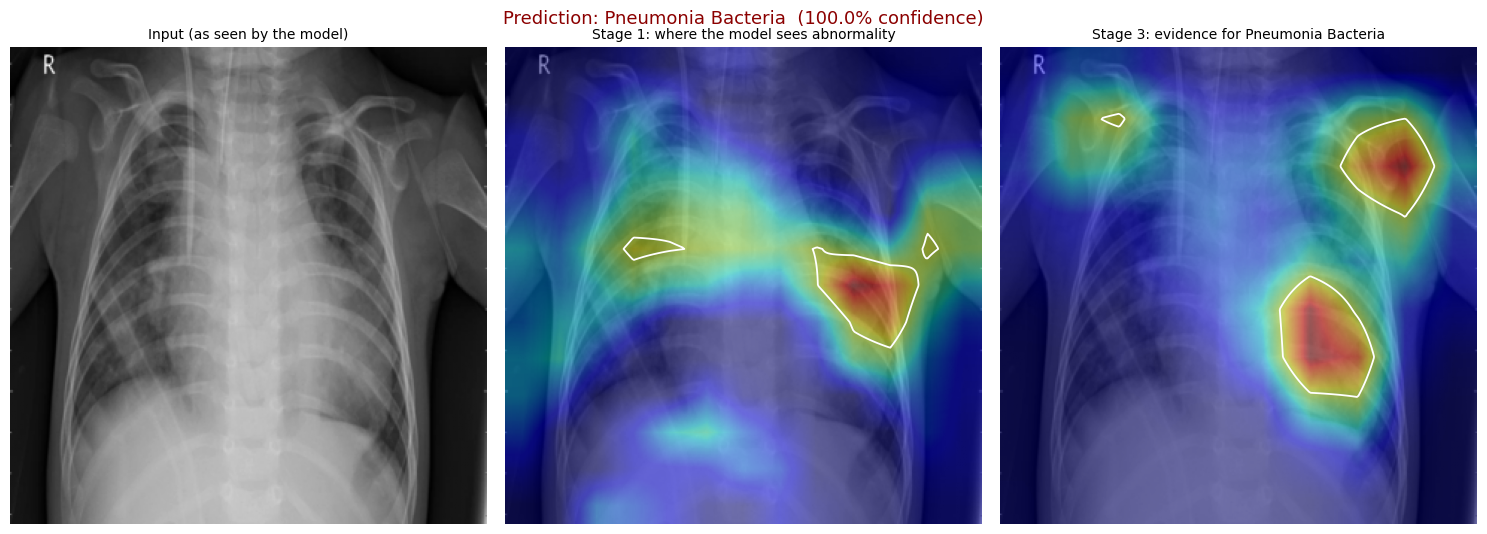

  Stage 1 (SqueezeNet)       -> Abnormal             confidence 100.0%
  Stage 2 (ResNet-50)        -> Non-COVID            confidence 100.0%
  Stage 3 (EfficientNet-b0)  -> Pneumonia Bacteria   confidence 100.0%
  Heat-map = regions that influenced the model (red = strong); white outline = strongest area.
  Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.


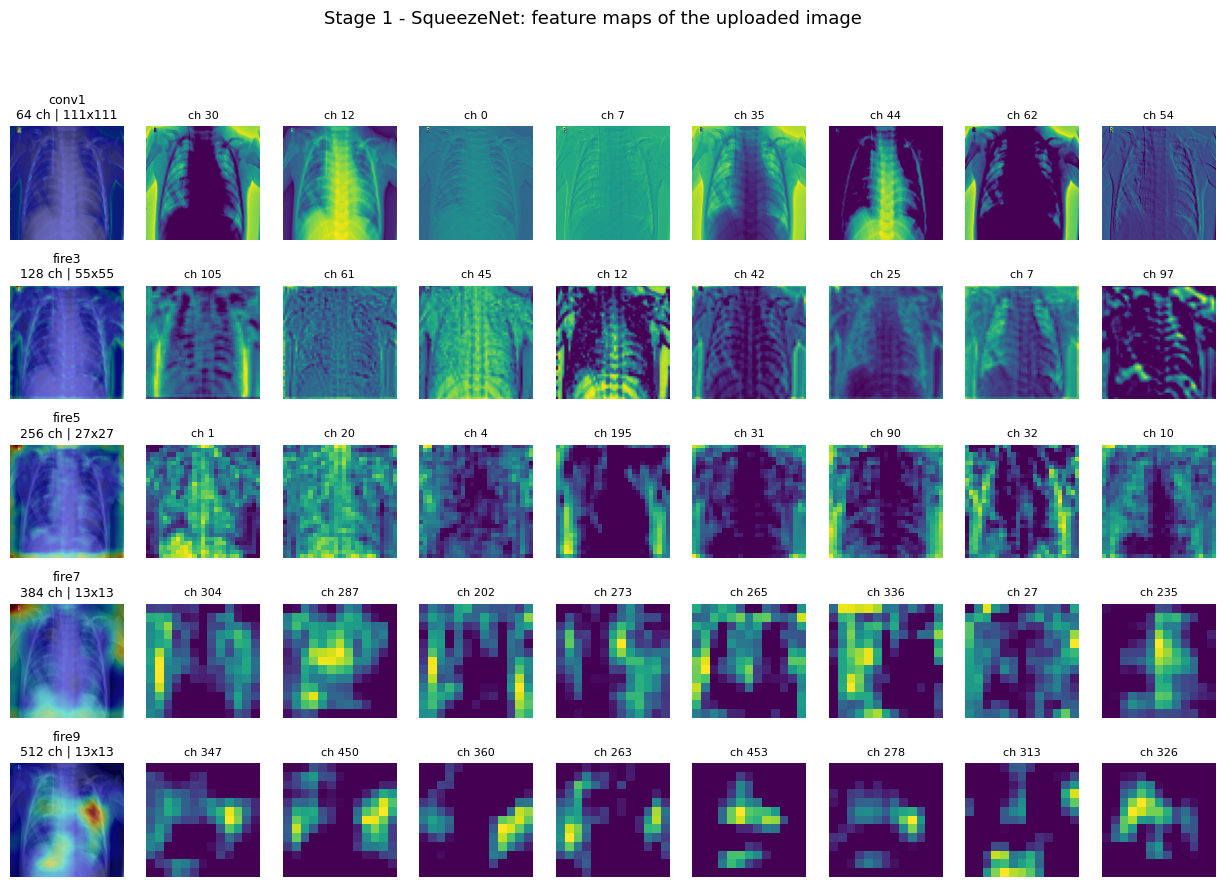

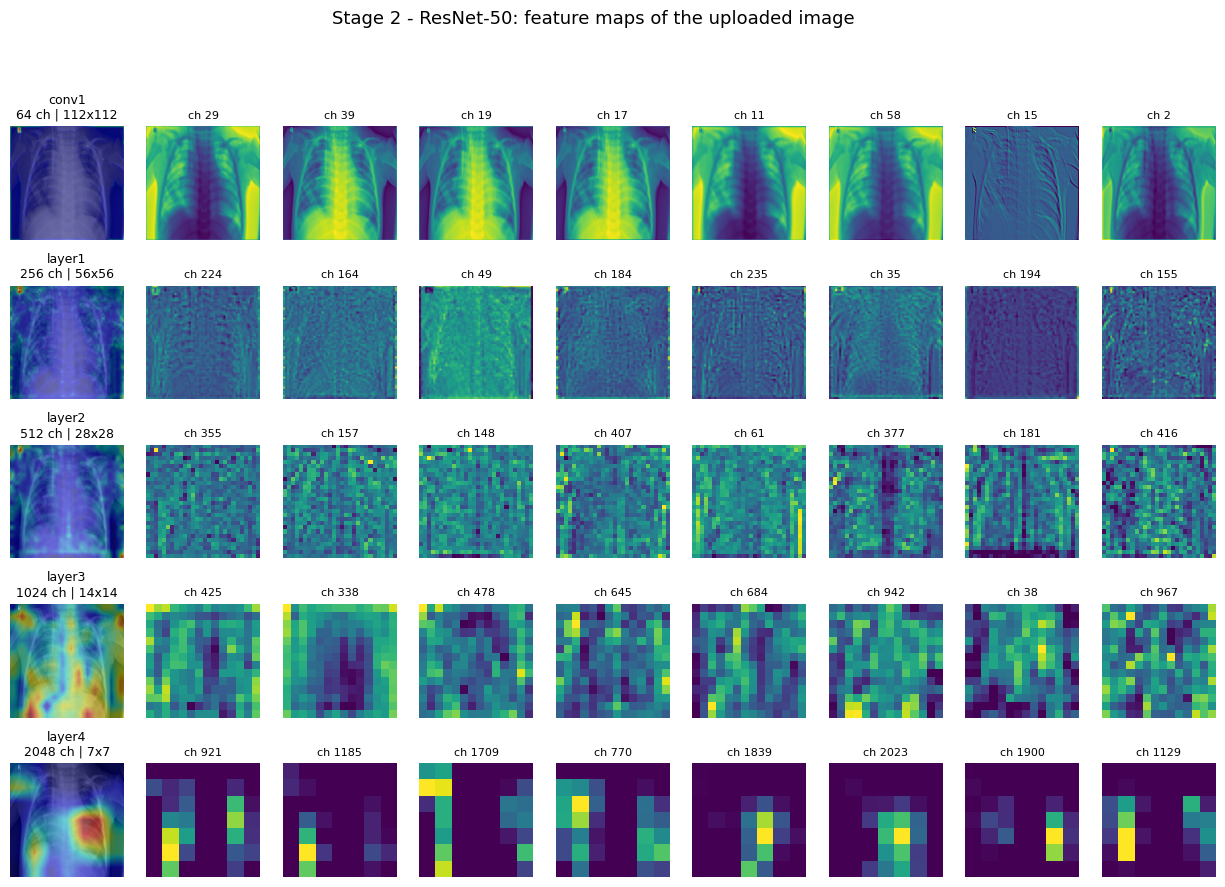

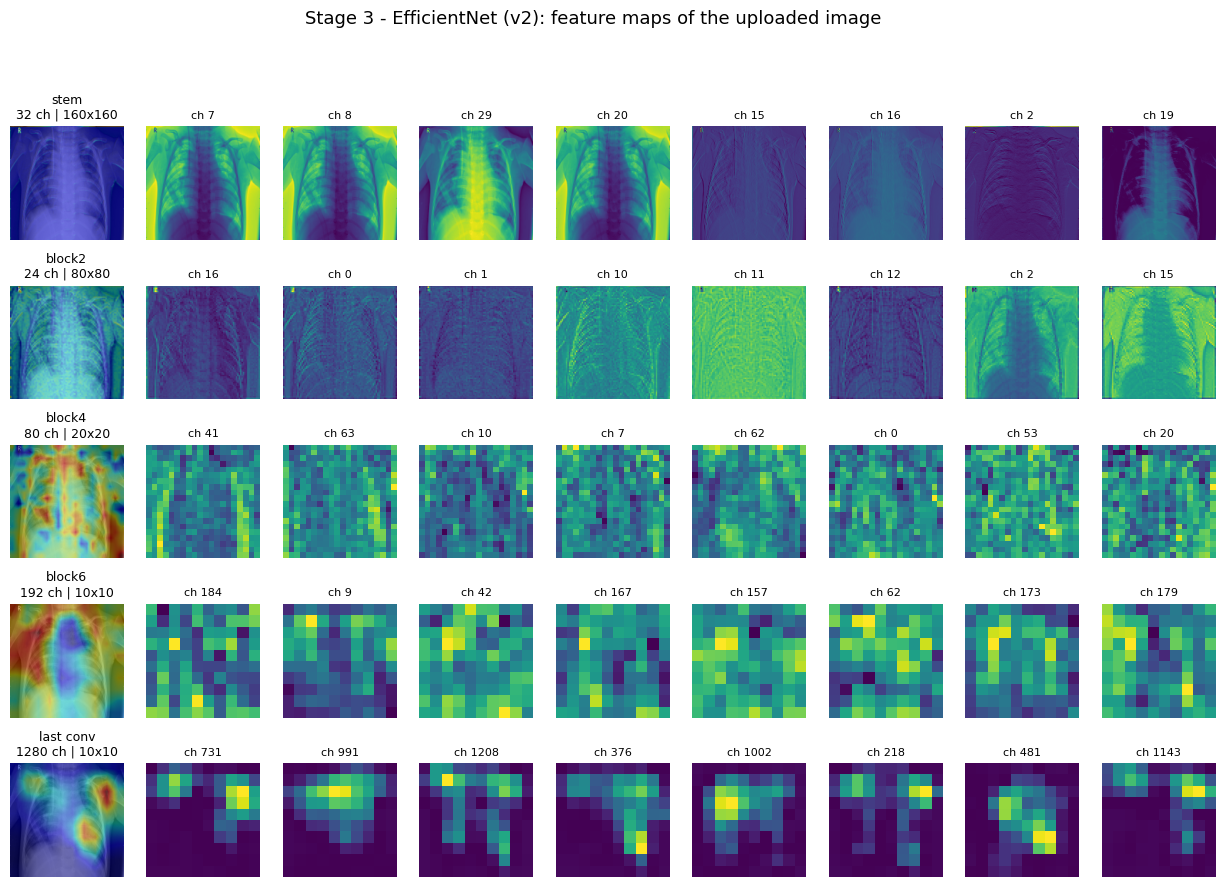

In [ ]:
from google.colab import files
uploaded = files.upload()
for fname in uploaded:
    print("\n=====", fname, "=====")
    predict_with_gradcam(fname)
    visualize_feature_maps(fname)

### 12.2 (optional) Grad-CAM demo on random dataset images - no upload needed


===== non_COVID (1321).png =====


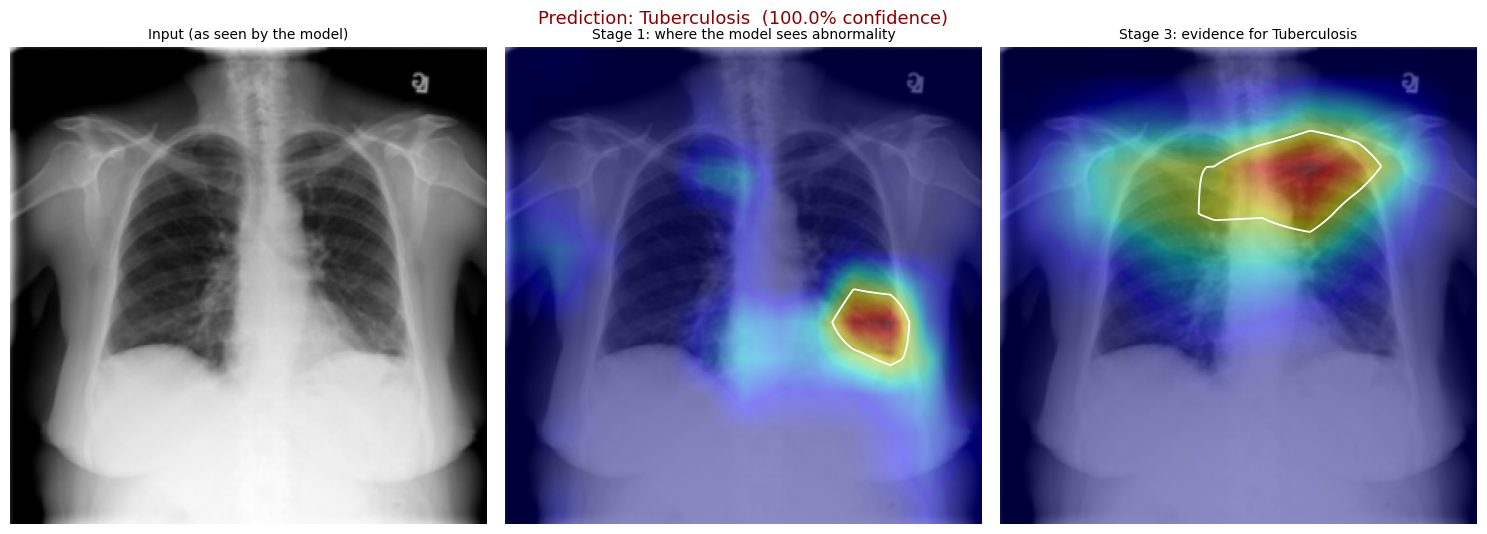

  Stage 1 (SqueezeNet)       -> Abnormal             confidence  63.8%
  Stage 2 (ResNet-50)        -> Non-COVID            confidence 100.0%
  Stage 3 (EfficientNet-b0)  -> Tuberculosis         confidence 100.0%
  Heat-map = regions that influenced the model (red = strong); white outline = strongest area.
  Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.

===== covid_1572.png =====


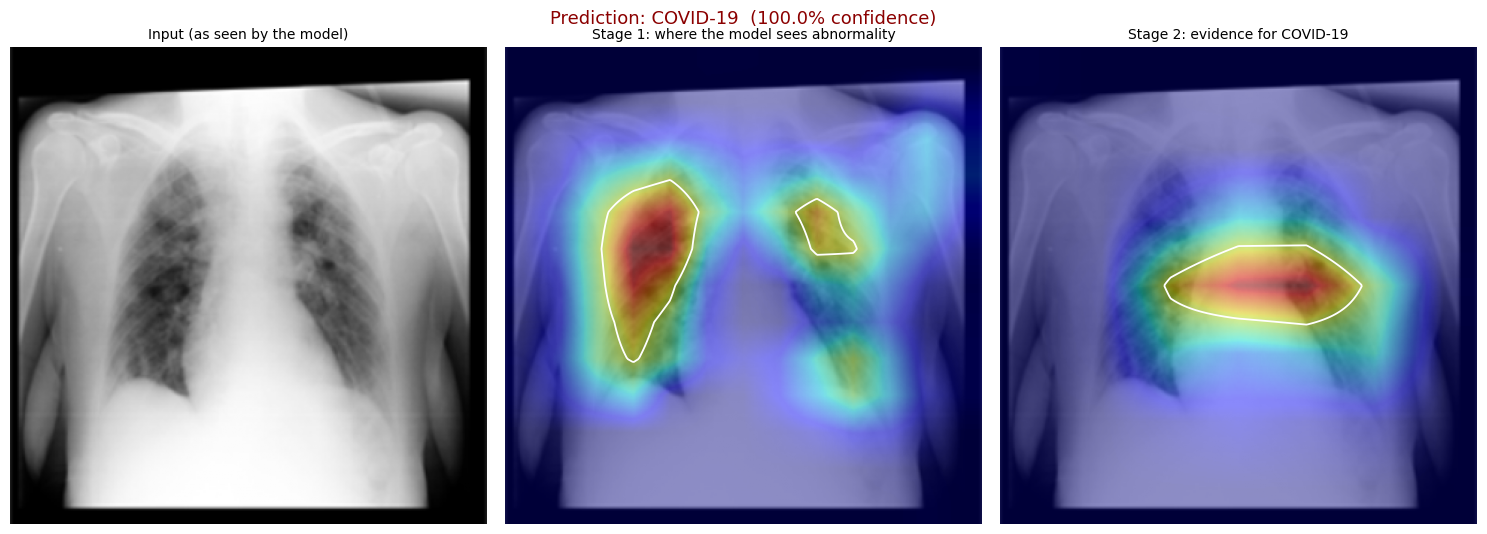

  Stage 1 (SqueezeNet)       -> Abnormal             confidence 100.0%
  Stage 2 (ResNet-50)        -> COVID-19             confidence 100.0%
  Heat-map = regions that influenced the model (red = strong); white outline = strongest area.
  Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.

===== covid_3427.png =====


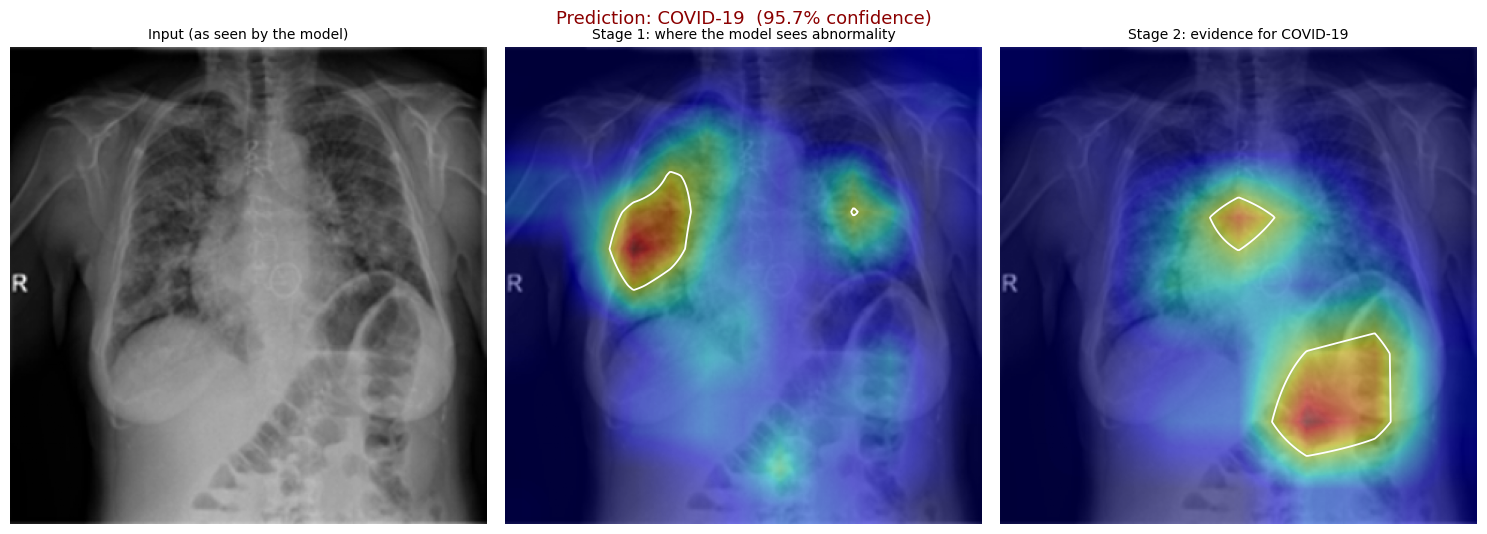

  Stage 1 (SqueezeNet)       -> Abnormal             confidence 100.0%
  Stage 2 (ResNet-50)        -> COVID-19             confidence  95.7%
  Heat-map = regions that influenced the model (red = strong); white outline = strongest area.
  Research prototype - not a medical diagnosis. Please consult a radiologist/doctor.


In [ ]:
for p in df[df.label_name == "Abnormal"].path.sample(3, random_state=1):
    print("\n=====", os.path.basename(p), "=====")
    predict_with_gradcam(p)

## 13. Download results (plots, CSVs, model weights)

In [ ]:
from google.colab import files
!zip -qr cxr_pipeline_results.zip results
files.download("cxr_pipeline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Website (GUI)
Whole notebook run aanadhum, kizhe irukkura 2 cells-a run pannunga -> website link open aagum.
Website-la: X-ray upload -> prediction + Grad-CAM, and a table + graphs of **Paper vs Ours** (Accuracy, Precision, Recall, F1, Specificity, AUC).

### 14.1 Write the website app file

In [ ]:
%%writefile cxr_gui_app.py
"""
3-Stage Chest X-ray Pipeline - GUI (Gradio)
Stage 1 SqueezeNet  : Normal vs Abnormal
Stage 2 ResNet-50   : COVID-19 vs Non-COVID
Stage 3 EfficientNet: Pneumonia Bacteria / Pneumonia Virus / Tuberculosis

Needs ONLY the 3 trained .pt files - no dataset, no training, no other notebook cells.

Usage (Colab):   !pip install -q gradio ; %run cxr_gui_app.py
Usage (own PC):  pip install torch torchvision gradio pandas matplotlib pillow ; python cxr_gui_app.py
"""
import os, sys, json, warnings
import numpy as np
import pandas as pd
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models
import matplotlib
try:
    from IPython import get_ipython
    _in_nb = get_ipython() is not None
except Exception:
    _in_nb = False
if not _in_nb:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import gradio as gr

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================================================
# CONFIG  (edit only this block)
# =====================================================================================
# folders searched (in order) for the .pt weight files
_APP_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
WEIGHT_DIRS = ["results", "weights", ".", "/content/results",
               "/content/drive/MyDrive/CXR_pipeline/results", "/content/drive/MyDrive/CXR_pipeline",
               os.path.join(_APP_DIR, "results"), os.path.join(_APP_DIR, "weights"), _APP_DIR]

# "v2" = optimised Stage 3 (320 px, file stage3v2_efficientnet_b0_best.pt, test acc 81.71 %)
# "v1" = first Stage 3     (224 px, file stage3_EfficientNet-b0_best.pt,   test acc 83.88 %)
STAGE3_VERSION = "v2"

# ---- ALL METRICS (%), paper vs ours.  Saved to metrics.json next to the weights on first run;
#      edit that json any time to type the paper's Table-4 values (None / null = shown as "-").
METRIC_KEYS = ["Accuracy", "Precision", "Recall", "F1-score", "Specificity", "AUC"]
DEFAULT_METRICS = {
    "paper": {   # Soft Computing 2026. Accuracy = abstract. Recall = 1 - FNR (FNR quoted in paper text, Sec. 7).
                 # Precision / F1 / Specificity / AUC are in the paper's Table 4 -> type them into metrics.json.
        "1": {"Accuracy": 99.0, "Precision": None, "Recall": 97.9, "F1-score": None, "Specificity": None, "AUC": None},
        "2": {"Accuracy": 98.0, "Precision": None, "Recall": 97.8, "F1-score": None, "Specificity": None, "AUC": None},
        "3": {"Accuracy": 97.0, "Precision": None, "Recall": 97.26, "F1-score": None, "Specificity": None, "AUC": None},
    },
    "ours": {    # from your notebook outputs (test set; Stage 3 = macro average)
        "1":   {"Accuracy": 92.32, "Precision": 97.66, "Recall": 90.96, "F1-score": 94.19, "Specificity": 95.27, "AUC": 97.77},
        "2":   {"Accuracy": 99.02, "Precision": 99.66, "Recall": 98.38, "F1-score": 99.02, "Specificity": 99.67, "AUC": 99.98},
        "3v1": {"Accuracy": 83.88, "Precision": 86.00, "Recall": 87.21, "F1-score": 86.45, "Specificity": None, "AUC": 93.43},
        "3v2": {"Accuracy": 81.71, "Precision": 84.36, "Recall": 82.84, "F1-score": 83.52, "Specificity": None, "AUC": 91.92},
    },
    "ours_stage3_per_class": {   # test set, precision / recall / f1 (%)
        "3v1": {"Pneumonia Bacteria": [88.86, 82.39, 85.51], "Pneumonia Virus": [69.14, 79.25, 73.85], "Tuberculosis": [100.0, 100.0, 100.0]},
        "3v2": {"Pneumonia Bacteria": [82.41, 86.85, 84.57], "Pneumonia Virus": [70.68, 63.68, 67.00], "Tuberculosis": [100.0, 98.00, 98.99]},
    },
    "train_val_test_acc": {
        "1": [94.06, 93.30, 92.32], "2": [99.83, 99.05, 99.02],
        "3v1": [83.29, 79.92, 83.88], "3v2": [90.49, 82.13, 81.71],
    },
}

STAGES = {
    1: dict(name="SqueezeNet",      arch="squeezenet", size=224, classes=["Abnormal", "Normal"],
            files=["stage1_SqueezeNet_best.pt"]),
    2: dict(name="ResNet-50",       arch="resnet50",   size=224, classes=["COVID-19", "Non-COVID"],
            files=["stage2_ResNet-50_best.pt"]),
    3: dict(name="EfficientNet-b0", arch="effnet_b0",  size=320 if STAGE3_VERSION == "v2" else 224,
            classes=["Pneumonia Bacteria", "Pneumonia Virus", "Tuberculosis"],
            files=(["stage3v2_efficientnet_b0_best.pt"] if STAGE3_VERSION == "v2"
                   else ["stage3_EfficientNet-b0_best.pt"])),
}

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


# =====================================================================================
# MODELS  (same heads as training, so the saved state_dicts load exactly)
# =====================================================================================
def build_model(arch, n_classes):
    if arch == "squeezenet":
        m = models.squeezenet1_1(weights=None)
        m.classifier = nn.Sequential(nn.Dropout(0.5), nn.Conv2d(512, n_classes, 1),
                                     nn.AdaptiveAvgPool2d(1), nn.Flatten())
    elif arch == "resnet50":
        m = models.resnet50(weights=None)
        m.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(m.fc.in_features, n_classes))
    elif arch == "effnet_b0":
        m = models.efficientnet_b0(weights=None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, n_classes))
    else:
        raise ValueError(arch)
    return m


def _mount_drive_if_possible():
    try:
        from google.colab import drive
        if not os.path.isdir("/content/drive/MyDrive"):
            drive.mount("/content/drive")
    except Exception:
        pass


def _find(fname):
    for d in WEIGHT_DIRS:
        p = os.path.join(d, fname)
        if os.path.isfile(p):
            return p
    return None


def load_pipeline():
    if any(_find(f) is None for s in STAGES.values() for f in s["files"]):
        _mount_drive_if_possible()
    pipe, missing = {}, []
    for k, s in STAGES.items():
        path = _find(s["files"][0])
        if path is None:
            missing.append(s["files"][0]); continue
        m = build_model(s["arch"], len(s["classes"]))
        m.load_state_dict(torch.load(path, map_location="cpu"))
        pipe[k] = m.to(device).eval()
        print(f"Stage {k}: {s['name']:<16} loaded from {path}")
    if missing:
        raise FileNotFoundError(
            "Weight file(s) not found: " + ", ".join(missing) +
            "\nSearched in: " + ", ".join(WEIGHT_DIRS) +
            "\n-> copy the .pt files into a 'results' folder (or Google Drive: MyDrive/CXR_pipeline/results).")
    return pipe


PIPE = load_pipeline()


def load_metrics():
    """metrics.json (if present) overrides the defaults key-by-key; if absent it is created next to the weights."""
    import copy
    m = copy.deepcopy(DEFAULT_METRICS)
    wdir = os.path.dirname(_find(STAGES[1]["files"][0]))
    path = os.path.join(wdir, "metrics.json")
    if os.path.isfile(path):
        try:
            user = json.load(open(path))
            for sec in ("paper", "ours"):
                for k, d in user.get(sec, {}).items():
                    m[sec].setdefault(k, {}).update(d)
            for sec in ("ours_stage3_per_class", "train_val_test_acc"):
                m[sec].update(user.get(sec, {}))
            print("metrics loaded from", path)
        except Exception as e:
            print("could not read", path, "->", e, "(using defaults)")
    else:
        try:
            json.dump(DEFAULT_METRICS, open(path, "w"), indent=2)
            print("metrics.json created at", path, "(edit it to add paper Table-4 values)")
        except Exception:
            pass
    return m


METRICS = load_metrics()
S3 = "3" + STAGE3_VERSION
def _m(who, stage, key):
    return METRICS[who].get(S3 if stage == 3 and who == "ours" else str(stage), {}).get(key)
def _fmt(v):
    return "-" if v is None else f"{v:.2f}%"
CAM_LAYERS = {1: PIPE[1].features[-1], 2: PIPE[2].layer4[-1], 3: PIPE[3].features[-1]}


# =====================================================================================
# PREPROCESSING + INFERENCE + GRAD-CAM
# =====================================================================================
def preprocess(pil_img, size):
    """Same as training: grayscale -> resize -> 3 channels -> ImageNet normalisation."""
    im = pil_img.convert("L").resize((size, size), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im, dtype=np.uint8)).unsqueeze(0).float().div(255).expand(3, -1, -1)
    return ((x - MEAN) / STD).unsqueeze(0).to(device), im


def grad_cam(model, layer, x, class_idx):
    store = {}

    def fwd_hook(module, inp, out):
        store["a"] = out.detach()
        out.register_hook(lambda g: store.__setitem__("g", g.detach()))

    h = layer.register_forward_hook(fwd_hook)
    try:
        model.eval(); model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(x.clone().float().requires_grad_(True))
            logits[0, class_idx].backward()
    finally:
        h.remove()
    a, g = store["a"][0], store["g"][0]
    cam = F.relu((g.mean(dim=(1, 2), keepdim=True) * a).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy()


def _fig_to_array(fig):
    fig.canvas.draw()
    arr = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return arr


def _cam_figure(inputs, cams, title, color):
    n = 1 + len(cams)
    fig, ax = plt.subplots(1, n, figsize=(4.6 * n, 5))
    ax = np.atleast_1d(ax)
    ax[0].imshow(inputs, cmap="gray"); ax[0].set_title("Input (as seen by the model)", fontsize=10); ax[0].axis("off")
    for a_, (t, im, cam) in zip(ax[1:], cams):
        a_.imshow(im, cmap="gray"); a_.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        a_.contour(cam, levels=[0.6], colors="white", linewidths=1.3)
        a_.set_title(t, fontsize=10); a_.axis("off")
    fig.suptitle(title, fontsize=13, color=color)
    fig.tight_layout()
    return _fig_to_array(fig)


def predict(pil_img):
    if pil_img is None:
        return "### Upload a chest X-ray first.", None, None, None
    pil_img = pil_img.convert("RGB")
    rows, cams = [], []

    def run(k, class_idx=None):
        x, im = preprocess(pil_img, STAGES[k]["size"])
        with torch.no_grad():
            p = F.softmax(PIPE[k](x).float(), 1)[0].cpu().numpy()
        return x, im, p

    def row(k, cls, conf):
        return [f"Stage {k}", STAGES[k]["name"], cls, f"{conf*100:.1f}%",
                _fmt(_m("paper", k, "Accuracy")), _fmt(_m("ours", k, "Accuracy")),
                _fmt(_m("paper", k, "F1-score")), _fmt(_m("ours", k, "F1-score"))]

    x1, im1, p1 = run(1); i1 = int(p1.argmax()); c1 = STAGES[1]["classes"][i1]
    rows.append(row(1, c1, p1[i1]))
    last_probs, last_classes = p1, STAGES[1]["classes"]
    if c1 == "Normal":
        final, conf = "Normal - no abnormality detected", p1[i1]
    else:
        cams.append(("Stage 1: where the model sees abnormality", im1, grad_cam(PIPE[1], CAM_LAYERS[1], x1, 0)))
        x2, im2, p2 = run(2); i2 = int(p2.argmax()); c2 = STAGES[2]["classes"][i2]
        rows.append(row(2, c2, p2[i2]))
        last_probs, last_classes = p2, STAGES[2]["classes"]
        if c2 == "COVID-19":
            final, conf = "COVID-19", p2[i2]
            cams.append((f"Stage 2: evidence for {final}", im2, grad_cam(PIPE[2], CAM_LAYERS[2], x2, i2)))
        else:
            x3, im3, p3 = run(3); i3 = int(p3.argmax()); c3 = STAGES[3]["classes"][i3]
            rows.append(row(3, c3, p3[i3]))
            last_probs, last_classes = p3, STAGES[3]["classes"]
            final, conf = c3, p3[i3]
            cams.append((f"Stage 3: evidence for {final}", im3, grad_cam(PIPE[3], CAM_LAYERS[3], x3, i3)))

    healthy = final.startswith("Normal")
    verdict = (f"## {'✅' if healthy else '⚠️'} Prediction: **{final}**  \n"
               f"Confidence of the deciding stage: **{conf*100:.1f}%**")
    label = {c: float(p) for c, p in zip(last_classes, last_probs)}
    table = pd.DataFrame(rows, columns=["Stage", "Model", "Prediction", "Confidence",
                                        "Paper acc", "Our acc", "Paper F1", "Our F1"])
    base_im = im1
    cam_img = _cam_figure(base_im, cams, f"Prediction: {final} ({conf*100:.1f}% confidence)",
                          "darkgreen" if healthy else "darkred") if cams else None
    return verdict, label, table, cam_img


# =====================================================================================
# PAPER vs OURS  (all metrics: table + charts)
# =====================================================================================
def metrics_table():
    rows = []
    for k in (1, 2, 3):
        for key in METRIC_KEYS:
            p, o = _m("paper", k, key), _m("ours", k, key)
            d = "-" if (p is None or o is None) else f"{o - p:+.2f}"
            rows.append([f"Stage {k} - {STAGES[k]['name']}", key, _fmt(p), _fmt(o), d])
    return pd.DataFrame(rows, columns=["Stage", "Metric", "Paper", "Ours (test)", "Ours - Paper"])


def split_table():
    return pd.DataFrame([[f"Stage {k} - {STAGES[k]['name']}"] + [f"{v:.2f}%" for v in
                          METRICS["train_val_test_acc"].get(S3 if k == 3 else str(k), [np.nan] * 3)]
                         for k in (1, 2, 3)], columns=["Stage", "Train acc", "Validation acc", "Test acc"])


def per_class_table():
    d = METRICS["ours_stage3_per_class"].get(S3, {})
    return pd.DataFrame([[c, f"{v[0]:.2f}%", f"{v[1]:.2f}%", f"{v[2]:.2f}%"] for c, v in d.items()],
                        columns=["Stage 3 class", "Precision", "Recall", "F1-score"])


def metrics_chart():
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    xs = np.arange(len(METRIC_KEYS)); w = 0.38
    for ax, k in zip(axes, (1, 2, 3)):
        p = [_m("paper", k, m) for m in METRIC_KEYS]; o = [_m("ours", k, m) for m in METRIC_KEYS]
        for i, (pv, ov) in enumerate(zip(p, o)):
            if pv is not None:
                ax.bar(i - w/2, pv, w, color="tab:gray", label="Paper" if i == 0 else None)
                ax.text(i - w/2, pv + 0.5, f"{pv:.1f}", ha="center", fontsize=7)
            if ov is not None:
                ax.bar(i + w/2, ov, w, color="tab:blue", label="Ours" if i == 0 else None)
                ax.text(i + w/2, ov + 0.5, f"{ov:.1f}", ha="center", fontsize=7)
        ax.set_xticks(xs); ax.set_xticklabels(METRIC_KEYS, rotation=30, fontsize=8)
        ax.set_title(f"Stage {k}: {STAGES[k]['name']}"); ax.grid(axis="y", alpha=.3); ax.set_ylim(60, 105)
    axes[0].set_ylabel("%"); h, l = axes[0].get_legend_handles_labels()
    by = dict(zip(l, h)); fig.legend(by.values(), by.keys(), loc="upper right")
    fig.suptitle("Paper vs Ours (bars missing = paper value not entered)"); fig.tight_layout()
    return _fig_to_array(fig)


# =====================================================================================
# GUI
# =====================================================================================
DISCLAIMER = ("*Research prototype - not a medical diagnosis. The heat-map shows where the model looked "
              "(red = strong influence); it is not a verified segmentation of the disease.*")

with gr.Blocks(title="Chest X-ray 3-Stage Pipeline", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🫁 3-Stage Chest X-ray Classifier\n"
                "`Normal?` → **SqueezeNet** → if abnormal → **ResNet-50** (COVID-19?) → if not → "
                "**EfficientNet-b0** (Bacterial pneumonia / Viral pneumonia / Tuberculosis)")
    with gr.Tab("🔍 Predict"):
        with gr.Row():
            with gr.Column(scale=1):
                inp = gr.Image(type="pil", label="Upload chest X-ray (JPG / PNG)")
                btn = gr.Button("Predict", variant="primary")
            with gr.Column(scale=1):
                verdict = gr.Markdown()
                label = gr.Label(label="Class probabilities (deciding stage)")
        table = gr.Dataframe(label="Stage-by-stage result  |  Paper vs Our accuracy", interactive=False)
        cam_out = gr.Image(label="Grad-CAM - region that drove the decision")
        gr.Markdown(DISCLAIMER)
        btn.click(predict, inp, [verdict, label, table, cam_out])
        inp.change(predict, inp, [verdict, label, table, cam_out])
    with gr.Tab("📊 Paper vs Ours - all metrics"):
        gr.Markdown("### Accuracy, Precision, Recall, F1, Specificity, AUC - base paper vs our models")
        gr.Dataframe(metrics_table(), interactive=False)
        gr.Image(metrics_chart(), show_label=False)
        gr.Markdown("### Our Train / Validation / Test accuracy")
        gr.Dataframe(split_table(), interactive=False)
        gr.Markdown("### Our Stage-3 per-class test results")
        gr.Dataframe(per_class_table(), interactive=False)
        gr.Markdown(
            "**Paper:** *Detection of COVID-19 & non-COVID diseases from chest X-rays using deep learning-based CNNs*, "
            "Soft Computing 30 (2026). Accuracy = 99 / 98 / 97 % (abstract); Recall = 1 - FNR from Sec. 7. "
            "Precision / F1 / Specificity / AUC are in the paper's Table 4 - add them to `metrics.json` "
            "(next to the weights) and restart the app.  \n"
            "**Not strictly comparable:** the paper tested on 100 images per stage; ours uses a 70/15/15 split "
            "(thousands of test images) and Stage 3 is a patient-level split. Stage-3 metrics are macro-averages.")


if __name__ == "__main__":
    if "google.colab" in sys.modules:
        demo.launch(share=True, debug=False)          # public link (valid while the Colab session lives)
    else:
        demo.launch(inbrowser=True)                   # your own PC -> opens http://127.0.0.1:7860 in the browser

Writing cxr_gui_app.py


### 14.2 Launch the website (open the public URL printed below)

In [ ]:
!pip install -q gradio
%run cxr_gui_app.py

Stage 1: SqueezeNet       loaded from results/stage1_SqueezeNet_best.pt
Stage 2: ResNet-50        loaded from results/stage2_ResNet-50_best.pt
Stage 3: EfficientNet-b0  loaded from results/stage3v2_efficientnet_b0_best.pt
metrics.json created at results/metrics.json (edit it to add paper Table-4 values)
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4740046954ada4a0c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<Figure size 640x480 with 0 Axes>

### 14.3 OPTIONAL - back up models to Google Drive (so you can reopen the website in a later session without retraining)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/CXR_pipeline/results
!cp results/*.pt results/metrics.json /content/drive/MyDrive/CXR_pipeline/results/
!cp cxr_gui_app.py /content/drive/MyDrive/CXR_pipeline/
# later session: !pip install -q gradio ; %run /content/drive/MyDrive/CXR_pipeline/cxr_gui_app.py

Mounted at /content/drive
